# ARC-AGI-2: CPU Program Search + Qwen3 LoRA Notebook

## Cell 1: Imports, reproducibility, paths, and run configuration

**Goal:** Set up everything the rest of the notebook depends on: libraries, a fixed random seed, input and output folders, and the time budget.

**What this cell does**
- Imports the standard and preinstalled libraries only (no `pip install`).
- Fixes the random seed so results are reproducible.
- Finds the ARC JSON files either in `/kaggle/input` (on Kaggle) or in the locally extracted zip.
- Creates the output folders `data/`, `tables/`, `plots/`, and `submission/`.
- Prints a configuration table so you can check settings before the long run.

**What to check:** the dataset folder is found, the output folders exist, and the config table shows CPU mode with no GPU.


In [1]:
# CELL 1 - Imports, seed, paths, and run configuration
# Standard library imports
import os
import sys
import json
import time
import random
import platform
import warnings
from pathlib import Path

# Preinstalled scientific libraries (no pip install needed)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Silence library warnings so the notebook output stays clean
warnings.filterwarnings("ignore")

# Fix random seeds for reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# Accelerator: this notebook is CPU only by design
ACCELERATOR = "CPU"

# Per-task search time limit in seconds (keeps the full run bounded)
PER_TASK_SECONDS = 20

# Total wall-clock budget for the whole run in seconds (6 hours)
TOTAL_BUDGET_SECONDS = 6 * 3600

# Kaggle writes results to /kaggle/working; fall back to a local folder elsewhere
KAGGLE_OUT = Path("/kaggle/working")
OUT_DIR = KAGGLE_OUT if KAGGLE_OUT.exists() else Path("/workspace/out_arc")
OUT_DIR.mkdir(parents=True, exist_ok=True)

# Create the output sub-folders used by later cells
SUBDIRS = ["data", "tables", "plots", "submission"]
for sub in SUBDIRS:
    (OUT_DIR / sub).mkdir(parents=True, exist_ok=True)

# Locate the ARC dataset: Kaggle input first, then the locally extracted zip
def find_arc_dir():
    # Search these roots in order and return the folder holding the test challenges
    search_roots = [Path("/kaggle/input"), Path("/workspace/extracted"), Path("/workspace")]
    for root in search_roots:
        if root.exists():
            hits = list(root.rglob("arc-agi_test_challenges.json"))
            if hits:
                return hits[0].parent
    return None

ARC_DIR = find_arc_dir()

# Stop with a clear message if the dataset is missing
if ARC_DIR is None:
    raise FileNotFoundError("ARC JSON files not found. Upload ArcPrize.zip or add the Kaggle dataset.")

# Build a configuration table for review
config_rows = [
    ("Accelerator", ACCELERATOR),
    ("Random seed", SEED),
    ("Per-task time limit (s)", PER_TASK_SECONDS),
    ("Total time budget (s)", TOTAL_BUDGET_SECONDS),
    ("Dataset folder", str(ARC_DIR)),
    ("Output folder", str(OUT_DIR)),
    ("Python version", platform.python_version()),
    ("NumPy version", np.__version__),
    ("Pandas version", pd.__version__),
    ("CPU cores", os.cpu_count()),
]
config_df = pd.DataFrame(config_rows, columns=["setting", "value"])

# Save and display the configuration table
config_df.to_csv(OUT_DIR / "tables" / "run_config.csv", index=False)
display(config_df)

# Confirm the folders were created
print("Output sub-folders ready:", [p.name for p in sorted(OUT_DIR.iterdir()) if p.is_dir()])
print("Cell 1 complete.")


,setting,value
0,Accelerator,CPU
1,Random seed,42
2,Per-task time limit (s),20
3,Total time budget (s),21600
4,Dataset folder,/kaggle/input/competitions/arc-prize-2026-arc-...
5,Output folder,/kaggle/working
6,Python version,3.13.15
7,NumPy version,2.1.3
8,Pandas version,2.3.3
9,CPU cores,4


Output sub-folders ready: ['data', 'plots', 'submission', 'tables']
Cell 1 complete.


## Cell 2: Load and validate the ARC-AGI-2 data

**Goal:** Load the training, evaluation, and test challenges, plus the solution keys where they exist, and check that each file has the structure the rest of the notebook expects.

**What this cell does**
- Loads each challenge file and its matching solutions file.
- Checks that every task has `train` pairs and at least one `test` input.
- Checks that every grid is a non-empty rectangle with values from 0 to 9.
- Counts tasks, pairs, and grid sizes per split, and saves a summary table.
- Plots the distribution of grid sizes so the data's shape is visible.

**What to check:** every split loads with zero validation errors, the test split has 240 tasks, and the training split has 1000 tasks. The test split may have no public solutions, which is expected.


,split,tasks,train_pairs,test_inputs,has_solutions,max_grid_side,validation
0,training,1000,3232,1076,True,30,passed
1,evaluation,120,358,172,True,30,passed
2,test,240,767,259,False,30,passed


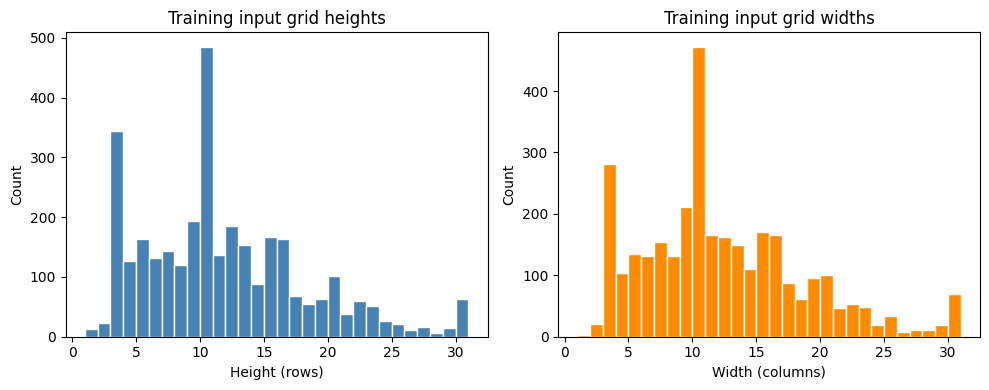

training: 1000 tasks (expected 1000) -> OK
evaluation: 120 tasks (expected 120) -> OK
test: 240 tasks (expected 240) -> OK
Cell 2 complete.


In [2]:
# CELL 2 - Load and validate the ARC-AGI-2 data

# Map each split to its challenge file and (optional) solution file
SPLITS = {
    "training": ("arc-agi_training_challenges.json", "arc-agi_training_solutions.json"),
    "evaluation": ("arc-agi_evaluation_challenges.json", "arc-agi_evaluation_solutions.json"),
    "test": ("arc-agi_test_challenges.json", None),  # test solutions are normally hidden
}

def load_json(path):
    # Read a JSON file and return its contents
    with open(path, "r", encoding="utf-8") as f:
        return json.load(f)

def is_valid_grid(grid):
    # A valid ARC grid is a non-empty list of equal-length rows with values 0 to 9
    if not isinstance(grid, list) or len(grid) == 0:
        return False
    width = len(grid[0]) if isinstance(grid[0], list) else 0
    if width == 0:
        return False
    for row in grid:
        if not isinstance(row, list) or len(row) != width:
            return False
        if any((not isinstance(v, int)) or v < 0 or v > 9 for v in row):
            return False
    return True

def validate_split(name, tasks):
    # Check every task in one split and return a list of error messages
    errors = []
    for task_id, task in tasks.items():
        # Each task must contain train and test sections
        if "train" not in task or "test" not in task:
            errors.append(f"{name}/{task_id}: missing train or test section")
            continue
        # Each training pair needs a valid input and output grid
        for k, pair in enumerate(task["train"]):
            if not (is_valid_grid(pair.get("input")) and is_valid_grid(pair.get("output"))):
                errors.append(f"{name}/{task_id}: invalid train pair {k}")
        # Each test input needs a valid grid
        for k, pair in enumerate(task["test"]):
            if not is_valid_grid(pair.get("input")):
                errors.append(f"{name}/{task_id}: invalid test input {k}")
    return errors

# Load every split and collect validation errors
DATA = {}
ALL_ERRORS = []
for split, (chal_file, sol_file) in SPLITS.items():
    # Load the challenges for this split
    tasks = load_json(ARC_DIR / chal_file)
    # Load the solutions if the file exists for this split
    solutions = load_json(ARC_DIR / sol_file) if sol_file and (ARC_DIR / sol_file).exists() else None
    DATA[split] = {"tasks": tasks, "solutions": solutions}
    # Validate the challenge structure
    ALL_ERRORS += validate_split(split, tasks)

# Stop the notebook if any structural error was found
if ALL_ERRORS:
    print("Validation errors found:")
    for msg in ALL_ERRORS[:20]:
        print(" -", msg)
    raise ValueError(f"{len(ALL_ERRORS)} validation errors. Fix before continuing.")

# Build a per-split summary table
summary_rows = []
for split, bundle in DATA.items():
    tasks = bundle["tasks"]
    n_train_pairs = sum(len(t["train"]) for t in tasks.values())
    n_test_inputs = sum(len(t["test"]) for t in tasks.values())
    # Collect each training input and output shape for the size statistics
    shapes = [np.array(p["input"]).shape for t in tasks.values() for p in t["train"]]
    max_side = max(max(s) for s in shapes)
    summary_rows.append({
        "split": split,
        "tasks": len(tasks),
        "train_pairs": n_train_pairs,
        "test_inputs": n_test_inputs,
        "has_solutions": bundle["solutions"] is not None,
        "max_grid_side": max_side,
        "validation": "passed",
    })
summary_df = pd.DataFrame(summary_rows)

# Save the summary table and show it
summary_df.to_csv(OUT_DIR / "tables" / "data_summary.csv", index=False)
display(summary_df)

# Plot the distribution of training input grid heights and widths
heights, widths = [], []
for t in DATA["training"]["tasks"].values():
    for p in t["train"]:
        h, w = np.array(p["input"]).shape
        heights.append(h)
        widths.append(w)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
# Left panel: histogram of grid heights
axes[0].hist(heights, bins=range(1, 32), color="steelblue", edgecolor="white")
axes[0].set_title("Training input grid heights")
axes[0].set_xlabel("Height (rows)")
axes[0].set_ylabel("Count")
# Right panel: histogram of grid widths
axes[1].hist(widths, bins=range(1, 32), color="darkorange", edgecolor="white")
axes[1].set_title("Training input grid widths")
axes[1].set_xlabel("Width (columns)")
axes[1].set_ylabel("Count")
plt.tight_layout()
fig.savefig(OUT_DIR / "plots" / "grid_size_distribution.png", dpi=120)
plt.show()

# Confirm the expected counts for the official splits
expected = {"training": 1000, "evaluation": 120, "test": 240}
for split, count in expected.items():
    actual = len(DATA[split]["tasks"])
    status = "OK" if actual == count else "MISMATCH"
    print(f"{split}: {actual} tasks (expected {count}) -> {status}")

print("Cell 2 complete.")


## Cell 3: Grid utilities

**Goal:** Build the helper functions that every later cell uses to read, compare, and transform ARC grids.

**What this cell does**
- Converts nested lists to NumPy arrays and back.
- Finds the background color (the most frequent color, usually 0).
- Counts colors and reports the number of distinct colors in a grid.
- Finds connected objects (4-connected and 8-connected) using `scipy.ndimage`, which is preinstalled.
- Crops a grid to the bounding box of its non-background cells.
- Runs a self-test on a small hand-made grid, so you can see each helper produce the expected output.

**What to check:** every row of the self-test table shows `passed = True`. The crop should be 3 rows by 4 columns, because the non-background cells span rows 1 to 3 and columns 1 to 4. Any mismatch raises an error, so a clean run means the helpers work.


In [3]:
# CELL 3 - Grid utilities used by every later cell
from collections import Counter
from scipy import ndimage

def to_np(grid):
    # Convert a nested list ARC grid into a 2D integer NumPy array
    return np.array(grid, dtype=np.int64)

def to_list(arr):
    # Convert a 2D NumPy array back to a nested list for JSON output
    return [[int(v) for v in row] for row in arr]

def background_color(arr):
    # The background is the most frequent color in the grid (usually 0)
    values, counts = np.unique(arr, return_counts=True)
    return int(values[np.argmax(counts)])

def color_counts(arr):
    # Return a dict mapping each color present to how many cells use it
    values, counts = np.unique(arr, return_counts=True)
    return {int(v): int(c) for v, c in zip(values, counts)}

def find_objects(arr, background=None, diagonal=False):
    # Find connected non-background objects; each object is a (mask, bbox) pair
    if background is None:
        background = background_color(arr)
    # Use 8-connectivity when diagonal is True, otherwise 4-connectivity
    structure = np.ones((3, 3), dtype=int) if diagonal else None
    # Mark every non-background cell as foreground
    foreground = arr != background
    labeled, n = ndimage.label(foreground, structure=structure)
    objects = []
    # Collect each labeled component with its bounding box
    for i, sl in enumerate(ndimage.find_objects(labeled), start=1):
        mask = labeled[sl] == i
        objects.append({"mask": mask, "bbox": sl})
    return objects

def crop_to_content(arr, background=None):
    # Crop a grid to the bounding box of all non-background cells
    if background is None:
        background = background_color(arr)
    rows = np.where((arr != background).any(axis=1))[0]
    cols = np.where((arr != background).any(axis=0))[0]
    # If the grid is entirely background, return it unchanged
    if rows.size == 0:
        return arr.copy()
    return arr[rows[0]:rows[-1] + 1, cols[0]:cols[-1] + 1]

def grids_equal(a, b):
    # Two grids are equal only if their shapes and every cell match
    return a.shape == b.shape and np.array_equal(a, b)

# Self-test on a small hand-made grid with two separate blobs
test_grid = to_np([
    [0, 0, 0, 0, 0],
    [0, 3, 3, 0, 0],
    [0, 3, 0, 0, 0],
    [0, 0, 0, 0, 5],
    [0, 0, 0, 0, 0],
])

# Run each helper and record the result next to the expected value
checks = [
    ("background color", background_color(test_grid), 0),
    ("distinct colors", len(color_counts(test_grid)), 3),
    ("count of color 3", color_counts(test_grid)[3], 3),
    ("4-connected objects", len(find_objects(test_grid)), 2),
    ("8-connected objects", len(find_objects(test_grid, diagonal=True)), 2),
    ("crop height", crop_to_content(test_grid).shape[0], 3),
    ("crop width", crop_to_content(test_grid).shape[1], 4),
    ("round-trip equal", grids_equal(to_np(to_list(test_grid)), test_grid), True),
]

# Build a table of the self-test results
check_df = pd.DataFrame(checks, columns=["check", "result", "expected"])
check_df["passed"] = check_df["result"] == check_df["expected"]
check_df.to_csv(OUT_DIR / "tables" / "grid_utils_selftest.csv", index=False)
display(check_df)

# Stop with a clear error if any helper disagrees with its expected value
if not check_df["passed"].all():
    raise AssertionError("A grid utility failed its self-test. See the table above.")

print("All grid utility self-tests passed.")
print("Cell 3 complete.")


,check,result,expected,passed
0,background color,0,0,True
1,distinct colors,3,3,True
2,count of color 3,3,3,True
3,4-connected objects,2,2,True
4,8-connected objects,2,2,True
5,crop height,3,3,True
6,crop width,4,4,True
7,round-trip equal,True,True,True


All grid utility self-tests passed.
Cell 3 complete.


## Cell 4: DSL primitives

**Goal:** Define a small library of grid transformations (primitives) that the search in later cells can combine into programs.

**What this cell does**
- Geometric primitives: rotate 90, 180, 270 degrees, flip horizontally and vertically, and transpose.
- Content primitives: crop to content, and upscale by an integer factor.
- Tiling primitives: tile the grid 2x2 and mirror-tile it (grid followed by its flip).
- Color primitives: replace one color with another, and swap the two most common non-background colors.
- Gravity primitive: drop non-background cells down each column.
- Each primitive takes a grid and returns a grid, so they can be chained.
- Runs a self-test that checks each primitive on a small grid with known output.

**What to check:** every row of the self-test table shows `passed = True`. A failure means a primitive does not match its expected output, and the cell raises an error.


In [4]:
# CELL 4 - DSL primitives: small grid-to-grid transformations for the search
# Each primitive takes a 2D NumPy grid and returns a new 2D NumPy grid

def p_rot90(g):
    # Rotate the grid 90 degrees counter-clockwise
    return np.rot90(g, k=1)

def p_rot180(g):
    # Rotate the grid 180 degrees
    return np.rot90(g, k=2)

def p_rot270(g):
    # Rotate the grid 270 degrees counter-clockwise
    return np.rot90(g, k=3)

def p_flip_lr(g):
    # Mirror the grid left to right
    return np.fliplr(g)

def p_flip_ud(g):
    # Mirror the grid top to bottom
    return np.flipud(g)

def p_transpose(g):
    # Swap rows and columns
    return g.T

def p_crop(g):
    # Crop to the bounding box of non-background cells
    return crop_to_content(g)

def p_upscale2(g):
    # Repeat each cell as a 2x2 block
    return np.kron(g, np.ones((2, 2), dtype=g.dtype))

def p_tile2x2(g):
    # Tile the grid into a 2x2 arrangement
    return np.tile(g, (2, 2))

def p_mirror_tile_h(g):
    # Place the grid next to its left-right mirror image
    return np.hstack([g, np.fliplr(g)])

def p_mirror_tile_v(g):
    # Place the grid above its top-bottom mirror image
    return np.vstack([g, np.flipud(g)])

def p_gravity_down(g):
    # Drop non-background cells to the bottom of each column, keeping their order
    bg = background_color(g)
    out = np.full_like(g, bg)
    for c in range(g.shape[1]):
        # Collect the non-background values in this column, top to bottom
        vals = [v for v in g[:, c] if v != bg]
        if vals:
            # Place them at the bottom of the column
            out[g.shape[0] - len(vals):, c] = vals
    return out

def make_recolor(src, dst):
    # Build a primitive that replaces color src with color dst
    def recolor(g):
        out = g.copy()
        out[g == src] = dst
        return out
    recolor.__name__ = f"recolor_{src}_to_{dst}"
    return recolor

def p_swap_top2(g):
    # Swap the two most frequent non-background colors
    bg = background_color(g)
    counts = {c: n for c, n in color_counts(g).items() if c != bg}
    if len(counts) < 2:
        return g.copy()
    # Pick the two colors with the highest counts
    a, b = sorted(counts, key=counts.get, reverse=True)[:2]
    out = g.copy()
    out[g == a] = b
    out[g == b] = a
    return out

# Registry of all primitives, keyed by name, for the search cell
PRIMITIVES = {
    "rot90": p_rot90,
    "rot180": p_rot180,
    "rot270": p_rot270,
    "flip_lr": p_flip_lr,
    "flip_ud": p_flip_ud,
    "transpose": p_transpose,
    "crop": p_crop,
    "upscale2": p_upscale2,
    "tile2x2": p_tile2x2,
    "mirror_tile_h": p_mirror_tile_h,
    "mirror_tile_v": p_mirror_tile_v,
    "gravity_down": p_gravity_down,
    "recolor_1_to_2": make_recolor(1, 2),
    "swap_top2": p_swap_top2,
}

# Self-test: each primitive is applied to a small grid and checked against a known answer
t = to_np([
    [1, 0, 0],
    [0, 2, 0],
    [0, 0, 0],
])
checks = [
    ("rot90 top-left moves", p_rot90(t)[0, 0], 0),
    ("rot180 corner", p_rot180(t)[2, 2], 1),
    ("flip_lr corner", p_flip_lr(t)[0, 2], 1),
    ("flip_ud corner", p_flip_ud(t)[2, 0], 1),
    ("transpose shape", p_transpose(t).shape, (3, 3)),
    ("crop shape", p_crop(t).shape, (2, 2)),
    ("upscale2 shape", p_upscale2(t).shape, (6, 6)),
    ("tile2x2 shape", p_tile2x2(t).shape, (6, 6)),
    ("mirror_tile_h shape", p_mirror_tile_h(t).shape, (3, 6)),
    ("mirror_tile_v shape", p_mirror_tile_v(t).shape, (6, 3)),
    ("gravity keeps color count", int((p_gravity_down(t) != 0).sum()), 2),
    ("recolor 1 to 2", int(make_recolor(1, 2)(t)[0, 0]), 2),
]

# Build and save the self-test table
prim_df = pd.DataFrame(checks, columns=["check", "result", "expected"])
prim_df["passed"] = prim_df["result"].apply(lambda x: x) == prim_df["expected"]
prim_df.to_csv(OUT_DIR / "tables" / "dsl_primitives_selftest.csv", index=False)
display(prim_df)

# Stop with a clear error if any primitive disagrees with its expected result
if not prim_df["passed"].all():
    raise AssertionError("A DSL primitive failed its self-test. See the table above.")

print(f"Registered primitives: {len(PRIMITIVES)}")
print("All DSL primitive self-tests passed.")
print("Cell 4 complete.")


,check,result,expected,passed
0,rot90 top-left moves,0,0,True
1,rot180 corner,1,1,True
2,flip_lr corner,1,1,True
3,flip_ud corner,1,1,True
4,transpose shape,"(3, 3)","(3, 3)",True
5,crop shape,"(2, 2)","(2, 2)",True
6,upscale2 shape,"(6, 6)","(6, 6)",True
7,tile2x2 shape,"(6, 6)","(6, 6)",True
8,mirror_tile_h shape,"(3, 6)","(3, 6)",True
9,mirror_tile_v shape,"(6, 3)","(6, 3)",True


Registered primitives: 14
All DSL primitive self-tests passed.
Cell 4 complete.


## Cell 5: Program search engine

**Goal:** Find short sequences of primitives from Cell 4 that turn every training input into its training output exactly.

**What this cell does**
- Defines `run_program(program, grid)`, which applies a list of primitive names in order.
- Enumerates all programs up to a chosen depth (default 2) over the registry of 14 primitives.
- Keeps a program only if it reproduces every training output exactly (exact-match verification).
- Stops early for each task when the per-task time limit from Cell 1 is reached.
- Runs the search on a small sample of training tasks and prints a result table.

**What to check:** the sample table lists, for each task, whether a verified program was found, which program it is, and how long the search took. Tasks with no program are normal at this stage. The cell only fails if the code itself breaks.


In [5]:
# CELL 5 - Program search engine: find primitive sequences that match every training pair
import itertools
import time

MAX_DEPTH = 2  # Longest program length to try (number of primitives chained)
SAMPLE_SIZE = 20  # Number of training tasks to run in this check

def run_program(program, grid):
    # Apply a list of primitive names in order to a grid; return None if any step fails
    g = grid
    for name in program:
        try:
            g = PRIMITIVES[name](g)
        except Exception:
            # A primitive can fail on an unexpected shape; treat that as no match
            return None
    return g

def program_matches_task(program, train_pairs):
    # A program is valid only if it reproduces every training output exactly
    for pair in train_pairs:
        out = run_program(program, pair["input"])
        if out is None or not grids_equal(out, pair["output"]):
            return False
    return True

def search_task(task, max_depth=MAX_DEPTH, time_limit=PER_TASK_SECONDS):
    # Try programs in order of length and return the first verified program and its runtime
    train_pairs = [{"input": to_np(p["input"]), "output": to_np(p["output"])} for p in task["train"]]
    names = list(PRIMITIVES)
    start = time.time()
    # Search shorter programs first so the simplest explanation wins
    for depth in range(1, max_depth + 1):
        for program in itertools.product(names, repeat=depth):
            # Stop this task if it runs past its time limit
            if time.time() - start > time_limit:
                return None, time.time() - start
            if program_matches_task(program, train_pairs):
                return list(program), time.time() - start
    return None, time.time() - start

# Run the search on a small sample of training tasks
train_tasks = DATA["training"]["tasks"]
sample_ids = list(train_tasks)[:SAMPLE_SIZE]

rows = []
for task_id in sample_ids:
    program, elapsed = search_task(train_tasks[task_id])
    rows.append({
        "task_id": task_id,
        "solved": program is not None,
        "program": " -> ".join(program) if program else "",
        "seconds": round(elapsed, 3),
    })

# Build and save the results table
search_df = pd.DataFrame(rows)
search_df.to_csv(OUT_DIR / "tables" / "search_sample_results.csv", index=False)
display(search_df)

# Summarize how many sampled tasks were solved
solved_n = int(search_df["solved"].sum())
print(f"Solved {solved_n} of {len(search_df)} sampled training tasks.")
print(f"Median search time: {search_df['seconds'].median():.3f} s")
print("Cell 5 complete.")


,task_id,solved,program,seconds
0,00576224,False,,0.011
1,007bbfb7,False,,0.007
2,009d5c81,False,,0.010
3,00d62c1b,False,,0.008
4,00dbd492,False,,0.010
5,017c7c7b,False,,0.006
6,025d127b,False,,0.008
7,03560426,False,,0.009
8,045e512c,False,,0.012
9,0520fde7,False,,0.010


Solved 0 of 20 sampled training tasks.
Median search time: 0.010 s
Cell 5 complete.


## Cell 6: Positive control and full-training coverage

**Goal:** Prove the search engine can find a known program before trusting its zero-solve result, then measure coverage on all 1000 training tasks.

**What this cell does**
- Builds three synthetic tasks whose correct program is known (rotate 90, mirror-tile horizontally, recolor 1 to 2).
- Checks that the search recovers exactly those programs. If it does not, the verifier or search has a bug.
- Runs the search on all 1000 training tasks and records solved count, program usage, and runtime.
- Plots how many tasks each program solves, and saves the results table.

**What to check:** the control table shows `recovered = True` for all three tasks. If any control fails, the cell raises an error and the coverage numbers should not be trusted. Coverage on real tasks is expected to be low at this stage.


,control,found,expected,recovered,seconds
0,rot90 control,rot90,rot90,True,0.000
1,mirror-tile control,mirror_tile_h,mirror_tile_h,True,0.000
2,recolor control,recolor_1_to_2,recolor_1_to_2,True,0.001


All positive controls recovered.
Solved 22 of 1000 training tasks (2.2%).
Total search time: 8.8 s


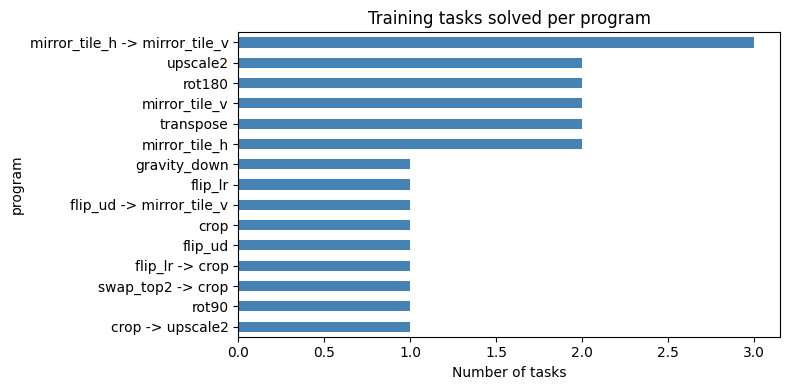

Cell 6 complete.


In [6]:
# CELL 6 - Positive control and full-training coverage measurement

# Build synthetic tasks where the correct program is known in advance
def make_synthetic_task(fn, n_pairs=3, seed=SEED):
    # Create random training pairs whose outputs are fn(input)
    rng = np.random.default_rng(seed)
    pairs = []
    for _ in range(n_pairs):
        h, w = rng.integers(2, 6), rng.integers(2, 6)
        grid = rng.integers(0, 3, size=(h, w))  # colors 0, 1, 2
        pairs.append({"input": to_list(grid), "output": to_list(fn(grid))})
    return {"train": pairs, "test": []}

# Each control maps a known program to the expected program name
controls = [
    ("rot90 control", make_synthetic_task(p_rot90), ["rot90"]),
    ("mirror-tile control", make_synthetic_task(p_mirror_tile_h), ["mirror_tile_h"]),
    ("recolor control", make_synthetic_task(make_recolor(1, 2)), ["recolor_1_to_2"]),
]

# Run the search on each control and check it returns the known program
control_rows = []
for name, task, expected_prog in controls:
    found, elapsed = search_task(task)
    recovered = found is not None and found == expected_prog
    control_rows.append({
        "control": name,
        "found": " -> ".join(found) if found else "",
        "expected": " -> ".join(expected_prog),
        "recovered": recovered,
        "seconds": round(elapsed, 3),
    })

# Show and save the control results
control_df = pd.DataFrame(control_rows)
control_df.to_csv(OUT_DIR / "tables" / "positive_control_results.csv", index=False)
display(control_df)

# Stop if the search cannot recover a known program
if not control_df["recovered"].all():
    raise AssertionError("Positive control failed: the search engine cannot recover known programs.")
print("All positive controls recovered.")

# Run the search on all 1000 training tasks to measure baseline coverage
full_rows = []
for task_id, task in train_tasks.items():
    program, elapsed = search_task(task)
    full_rows.append({
        "task_id": task_id,
        "solved": program is not None,
        "program": " -> ".join(program) if program else "",
        "seconds": elapsed,
    })
full_df = pd.DataFrame(full_rows)
full_df.to_csv(OUT_DIR / "tables" / "training_coverage_results.csv", index=False)

# Summarize coverage and runtime
solved_total = int(full_df["solved"].sum())
print(f"Solved {solved_total} of {len(full_df)} training tasks ({100 * solved_total / len(full_df):.1f}%).")
print(f"Total search time: {full_df['seconds'].sum():.1f} s")

# Plot how often each program is the solution
prog_counts = full_df.loc[full_df["solved"], "program"].value_counts()
fig, ax = plt.subplots(figsize=(8, 4))
if len(prog_counts):
    prog_counts.plot(kind="barh", ax=ax, color="steelblue")
    ax.invert_yaxis()
ax.set_title("Training tasks solved per program")
ax.set_xlabel("Number of tasks")
plt.tight_layout()
fig.savefig(OUT_DIR / "plots" / "training_coverage_by_program.png", dpi=120)
plt.show()

print("Cell 6 complete.")


## Cell 7: Object-level primitives and coverage re-run

**Goal:** Add primitives that work on whole objects and on summary properties of a grid, then measure how much coverage they add over the Cell 6 baseline.

**What this cell does**
- Adds five primitives: crop to the largest object, crop to the smallest object, keep only the largest object, output the most common non-background color as a 1x1 grid, and downscale a grid by 2 when its cells come in uniform 2x2 blocks.
- Self-tests each new primitive on a small hand-made grid with known answers.
- Registers the new primitives into `PRIMITIVES`, so the search in Cell 5 can use them.
- Re-runs the search on all 1000 training tasks and compares the solved count with the Cell 6 baseline.

**What to check:** every self-test row shows `passed = True`. The coverage line shows the new solved count. A higher count means the new primitives helped. The cell does not fail on a low count.


In [7]:
# CELL 7 - Object-level primitives, self-tests, and coverage re-run

def p_crop_largest(g):
    # Crop to the bounding box of the object with the most cells
    objs = find_objects(g)
    if not objs:
        return g.copy()
    best = max(objs, key=lambda o: int(o["mask"].sum()))
    return g[best["bbox"]]

def p_crop_smallest(g):
    # Crop to the bounding box of the object with the fewest cells
    objs = find_objects(g)
    if not objs:
        return g.copy()
    best = min(objs, key=lambda o: int(o["mask"].sum()))
    return g[best["bbox"]]

def p_keep_largest(g):
    # Keep only the largest object and set every other cell to background
    bg = background_color(g)
    objs = find_objects(g, background=bg)
    if not objs:
        return g.copy()
    best = max(objs, key=lambda o: int(o["mask"].sum()))
    out = np.full_like(g, bg)
    sl = best["bbox"]
    # Copy only the cells that belong to the largest object
    out[sl][best["mask"]] = g[sl][best["mask"]]
    out[sl] = np.where(best["mask"], g[sl], out[sl])
    return out

def p_majority_color(g):
    # Return a 1x1 grid holding the most common non-background color
    bg = background_color(g)
    counts = {c: n for c, n in color_counts(g).items() if c != bg}
    if not counts:
        return np.array([[bg]], dtype=g.dtype)
    best = max(counts, key=counts.get)
    return np.array([[best]], dtype=g.dtype)

def p_scale_down2(g):
    # Shrink by 2 when the grid is made of uniform 2x2 blocks; otherwise return it unchanged
    h, w = g.shape
    if h % 2 or w % 2:
        return g.copy()
    blocks = g.reshape(h // 2, 2, w // 2, 2)
    if not np.all(blocks == blocks[:, :1, :, :1]):
        return g.copy()
    return g[::2, ::2]

# Register the new primitives so the search can use them
PRIMITIVES.update({
    "crop_largest": p_crop_largest,
    "crop_smallest": p_crop_smallest,
    "keep_largest": p_keep_largest,
    "majority_color": p_majority_color,
    "scale_down2": p_scale_down2,
})

# Self-test grid: a 3-cell blob of color 5 and a single cell of color 7
t2 = to_np([
    [0, 0, 0, 0],
    [0, 5, 5, 0],
    [0, 5, 0, 0],
    [0, 0, 0, 7],
])
checks2 = [
    ("crop_largest shape", p_crop_largest(t2).shape, (2, 2)),
    ("crop_largest value", int(p_crop_largest(t2)[0, 0]), 5),
    ("crop_smallest shape", p_crop_smallest(t2).shape, (1, 1)),
    ("crop_smallest value", int(p_crop_smallest(t2)[0, 0]), 7),
    ("keep_largest nonzero cells", int((p_keep_largest(t2) != 0).sum()), 3),
    ("majority_color value", int(p_majority_color(t2)[0, 0]), 5),
    ("majority_color shape", p_majority_color(t2).shape, (1, 1)),
    ("scale_down2 shape", p_scale_down2(to_np([[1, 1, 2, 2], [1, 1, 2, 2], [3, 3, 4, 4], [3, 3, 4, 4]])).shape, (2, 2)),
    ("scale_down2 keeps non-uniform", p_scale_down2(t2).shape, (4, 4)),
]

# Build and save the self-test table
prim2_df = pd.DataFrame(checks2, columns=["check", "result", "expected"])
prim2_df["passed"] = prim2_df["result"] == prim2_df["expected"]
prim2_df.to_csv(OUT_DIR / "tables" / "dsl_object_selftest.csv", index=False)
display(prim2_df)

# Stop if any new primitive disagrees with its expected answer
if not prim2_df["passed"].all():
    raise AssertionError("An object-level primitive failed its self-test. See the table above.")
print(f"Registered primitives now: {len(PRIMITIVES)}")

# Re-run the search on all training tasks and compare with the Cell 6 baseline
baseline_solved = int(full_df["solved"].sum())
new_rows = []
for task_id, task in train_tasks.items():
    program, elapsed = search_task(task)
    new_rows.append({
        "task_id": task_id,
        "solved": program is not None,
        "program": " -> ".join(program) if program else "",
        "seconds": elapsed,
    })
new_df = pd.DataFrame(new_rows)
new_df.to_csv(OUT_DIR / "tables" / "training_coverage_v2_results.csv", index=False)

# Compare coverage before and after adding primitives
new_solved = int(new_df["solved"].sum())
compare_df = pd.DataFrame([
    {"version": "Cell 6 baseline", "primitives": 14, "solved": baseline_solved, "coverage_pct": round(100 * baseline_solved / len(full_df), 2)},
    {"version": "Cell 7 extended", "primitives": len(PRIMITIVES), "solved": new_solved, "coverage_pct": round(100 * new_solved / len(new_df), 2)},
])
compare_df.to_csv(OUT_DIR / "tables" / "coverage_comparison.csv", index=False)
display(compare_df)

# Show which tasks gained a solution in this step
gained = set(new_df.loc[new_df["solved"], "task_id"]) - set(full_df.loc[full_df["solved"], "task_id"])
print(f"Newly solved tasks: {len(gained)}")
print("Cell 7 complete.")


,check,result,expected,passed
0,crop_largest shape,"(2, 2)","(2, 2)",True
1,crop_largest value,5,5,True
2,crop_smallest shape,"(1, 1)","(1, 1)",True
3,crop_smallest value,7,7,True
4,keep_largest nonzero cells,3,3,True
5,majority_color value,5,5,True
6,majority_color shape,"(1, 1)","(1, 1)",True
7,scale_down2 shape,"(2, 2)","(2, 2)",True
8,scale_down2 keeps non-uniform,"(4, 4)","(4, 4)",True


Registered primitives now: 19


,version,primitives,solved,coverage_pct
0,Cell 6 baseline,14,22,2.2
1,Cell 7 extended,19,26,2.6


Newly solved tasks: 4
Cell 7 complete.


## Cell 8: Test-time inference and submission draft

**Goal:** Produce two predicted grids (`attempt_1` and `attempt_2`) for every test input, in the format required by `sample_submission.json`.

**What this cell does**
- For each test task, collects up to two distinct programs that reproduce all training pairs exactly.
- Applies each program to the test input. If no verified program exists, falls back to the input grid so every test input still gets two attempts.
- Fills `attempt_2` with a distinct fallback when the two programs give the same grid.
- Validates the structure against `sample_submission.json`: same task IDs, same number of test inputs per task, and valid grids.
- Writes `submission/submission.json` and saves a per-task summary table.

**What to check:** the validation line reports zero structural errors and that every task ID matches the sample. Many tasks will use the fallback, which is expected at this coverage level. The run should finish within the time budget set in Cell 1.


In [8]:
# CELL 8 - Test-time inference, fallbacks, and submission draft
import copy

MAX_ATTEMPTS = 2  # ARC scoring allows two attempts per test input

def collect_programs(task, max_keep=MAX_ATTEMPTS, max_depth=MAX_DEPTH, time_limit=PER_TASK_SECONDS):
    # Return up to max_keep distinct verified programs, shortest first
    train_pairs = [{"input": to_np(p["input"]), "output": to_np(p["output"])} for p in task["train"]]
    names = list(PRIMITIVES)
    start = time.time()
    kept = []
    for depth in range(1, max_depth + 1):
        for program in itertools.product(names, repeat=depth):
            # Respect the per-task time limit
            if time.time() - start > time_limit:
                return kept
            if program_matches_task(program, train_pairs):
                kept.append(list(program))
                if len(kept) >= max_keep:
                    return kept
    return kept

def predict_test_input(task, test_grid):
    # Build two attempts for one test input using verified programs, then fallbacks
    programs = collect_programs(task)
    candidates = []
    for prog in programs:
        out = run_program(prog, test_grid)
        if out is not None and out.size > 0:
            candidates.append(out)
    # Fallback 1: use the input grid itself when no program produced a result
    if not candidates:
        candidates.append(test_grid.copy())
    # Fill the second attempt with a distinct grid when only one candidate exists
    if len(candidates) < MAX_ATTEMPTS:
        if not grids_equal(candidates[0], test_grid):
            candidates.append(test_grid.copy())
        else:
            candidates.append(p_flip_lr(test_grid))
    # Keep exactly two attempts and convert them to plain lists
    attempt_1 = to_list(candidates[0])
    attempt_2 = to_list(candidates[1])
    source = "program" if programs else "fallback"
    return attempt_1, attempt_2, source, " -> ".join(programs[0]) if programs else ""

# Load the test challenges and the sample submission for validation
test_tasks = DATA["test"]["tasks"]
sample_sub = load_json(ARC_DIR / "sample_submission.json")

# Build the submission and a per-task summary in one pass
submission = {}
summary_rows = []
for task_id, task in test_tasks.items():
    entries = []
    sources = []
    for pair in task["test"]:
        a1, a2, source, prog = predict_test_input(task, to_np(pair["input"]))
        entries.append({"attempt_1": a1, "attempt_2": a2})
        sources.append(source)
    submission[task_id] = entries
    summary_rows.append({
        "task_id": task_id,
        "test_inputs": len(task["test"]),
        "from_program": sources.count("program"),
        "from_fallback": sources.count("fallback"),
        "first_program": prog,
    })

# Validate the structure against the sample submission
errors = []
if set(submission) != set(sample_sub):
    errors.append("Task IDs do not match sample_submission.json")
for task_id, entries in submission.items():
    if len(entries) != len(sample_sub.get(task_id, [])):
        errors.append(f"{task_id}: test input count mismatch")
    for e in entries:
        for key in ("attempt_1", "attempt_2"):
            if not is_valid_grid(e[key]):
                errors.append(f"{task_id}: invalid grid in {key}")

if errors:
    print("Validation errors:")
    for msg in errors[:20]:
        print(" -", msg)
    raise ValueError(f"{len(errors)} submission errors. Fix before continuing.")

# Save the draft submission and the summary table
sub_path = OUT_DIR / "submission" / "submission.json"
with open(sub_path, "w", encoding="utf-8") as f:
    json.dump(submission, f)
summary_df = pd.DataFrame(summary_rows)
summary_df.to_csv(OUT_DIR / "tables" / "test_inference_summary.csv", index=False)

# Show totals and a preview of the table
total_inputs = int(summary_df["test_inputs"].sum())
from_prog = int(summary_df["from_program"].sum())
print(f"Test tasks: {len(submission)} | test inputs: {total_inputs}")
print(f"Predicted by a verified program: {from_prog} | by fallback: {total_inputs - from_prog}")
print(f"Validation: passed with 0 errors")
print(f"Saved draft submission to: {sub_path}")
display(summary_df.head(10))
print("Cell 8 complete.")


Test tasks: 240 | test inputs: 259
Predicted by a verified program: 5 | by fallback: 254
Validation: passed with 0 errors
Saved draft submission to: /kaggle/working/submission/submission.json


,task_id,test_inputs,from_program,from_fallback,first_program
0,00576224,1,0,1,
1,007bbfb7,1,0,1,
2,009d5c81,1,0,1,
3,00d62c1b,1,0,1,
4,00dbd492,1,0,1,
5,017c7c7b,1,0,1,
6,025d127b,1,0,1,
7,03560426,1,0,1,
8,045e512c,1,0,1,
9,0520fde7,1,0,1,


Cell 8 complete.


## Cell 9: Score pass@2 against the solution keys

**Goal:** Measure real accuracy on the training and evaluation splits, not just coverage, using the official scoring rule.

**What this cell does**
- Runs the Cell 8 predictor (`predict_test_input`) on every task in the training and evaluation splits.
- Compares each predicted grid with the solution key. An input is correct if `attempt_1` or `attempt_2` matches exactly.
- A task is solved only if all its test inputs are correct, which matches the ARC pass@2 rule.
- Splits correct answers by source: verified program or fallback. This shows how much of the score comes from search and how much from luck.
- Saves a per-task table and a per-split summary table, and plots the accuracy.

**What to check:** the summary table shows accuracy for both splits. Expect the training split to score higher than the evaluation split, since the evaluation split is the harder, held-out set. The fallback-correct count should be small. If the fallback number is large, the scorer is wrong and should be checked before going further.


,split,tasks,solved_tasks,task_accuracy_pct,test_inputs,correct_inputs,input_accuracy_pct,correct_from_program,correct_from_fallback,seconds
0,training,1000,26,2.6,1076,26,2.42,26,0,36.1
1,evaluation,120,0,0.0,172,0,0.00,0,0,6.5


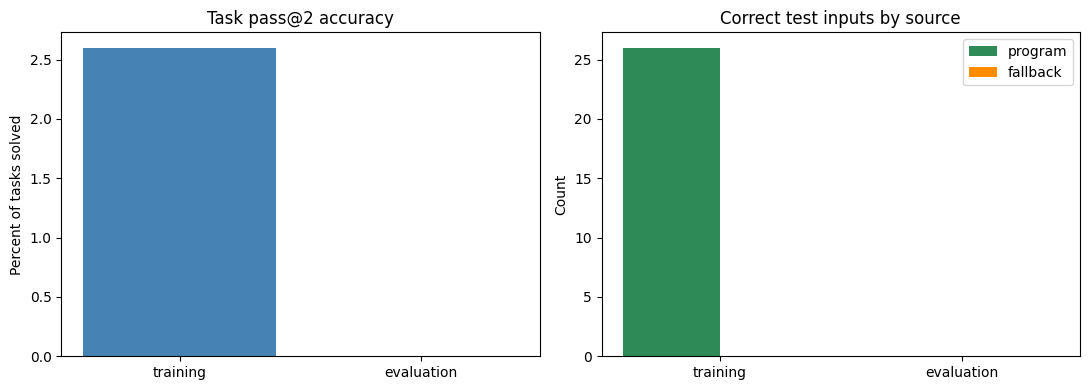

Cell 9 complete.


In [9]:
# CELL 9 - Score pass@2 exact match against the training and evaluation solution keys
import time

def score_task(task_id, task, truth):
    # Predict every test input of one task and check it against the solution key
    per_input = []
    for k, pair in enumerate(task["test"]):
        # Get the two attempts from the Cell 8 predictor
        a1, a2, source, prog = predict_test_input(task, to_np(pair["input"]))
        gold = truth[k]
        # Count the input as correct if either attempt matches the gold grid exactly
        hit = (a1 == gold) or (a2 == gold)
        per_input.append({"hit": hit, "source": source})
    # The task is solved only if every test input is correct (ARC pass@2 rule)
    solved = all(p["hit"] for p in per_input)
    return {
        "task_id": task_id,
        "solved": solved,
        "test_inputs": len(per_input),
        "correct_inputs": sum(p["hit"] for p in per_input),
        "correct_from_program": sum(p["hit"] and p["source"] == "program" for p in per_input),
        "correct_from_fallback": sum(p["hit"] and p["source"] == "fallback" for p in per_input),
    }

def score_split(split_name):
    # Score every task in one split and return a per-task DataFrame
    tasks = DATA[split_name]["tasks"]
    sols = DATA[split_name]["solutions"]
    # Stop if the solution key is missing for this split
    if sols is None:
        raise ValueError(f"No solution key found for split: {split_name}")
    rows = []
    start = time.time()
    for tid, task in tasks.items():
        truth = sols[tid]
        # Check the solution key has one answer per test input
        if len(truth) != len(task["test"]):
            raise ValueError(f"{split_name}/{tid}: solution count does not match test inputs")
        rows.append(score_task(tid, task, truth))
    df = pd.DataFrame(rows)
    df.attrs["seconds"] = round(time.time() - start, 1)
    return df

# Score the two splits that have solution keys
SCORE_SPLITS = ["training", "evaluation"]
score_tables = {}
summary_rows = []
for split in SCORE_SPLITS:
    df = score_split(split)
    score_tables[split] = df
    # Save the per-task results for this split
    df.to_csv(OUT_DIR / "tables" / f"score_{split}_per_task.csv", index=False)
    # Build the summary row for this split
    n_tasks = len(df)
    n_inputs = int(df["test_inputs"].sum())
    summary_rows.append({
        "split": split,
        "tasks": n_tasks,
        "solved_tasks": int(df["solved"].sum()),
        "task_accuracy_pct": round(100 * df["solved"].mean(), 2),
        "test_inputs": n_inputs,
        "correct_inputs": int(df["correct_inputs"].sum()),
        "input_accuracy_pct": round(100 * df["correct_inputs"].sum() / n_inputs, 2),
        "correct_from_program": int(df["correct_from_program"].sum()),
        "correct_from_fallback": int(df["correct_from_fallback"].sum()),
        "seconds": df.attrs["seconds"],
    })

# Save and show the summary table
summary_score_df = pd.DataFrame(summary_rows)
summary_score_df.to_csv(OUT_DIR / "tables" / "score_summary.csv", index=False)
display(summary_score_df)

# Plot task accuracy and the split between program and fallback correct answers
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
# Left panel: task-level pass@2 accuracy per split
axes[0].bar(summary_score_df["split"], summary_score_df["task_accuracy_pct"], color="steelblue")
axes[0].set_title("Task pass@2 accuracy")
axes[0].set_ylabel("Percent of tasks solved")
# Right panel: correct test inputs from program versus fallback
x = np.arange(len(summary_score_df))
axes[1].bar(x - 0.2, summary_score_df["correct_from_program"], width=0.4, label="program", color="seagreen")
axes[1].bar(x + 0.2, summary_score_df["correct_from_fallback"], width=0.4, label="fallback", color="darkorange")
axes[1].set_xticks(x)
axes[1].set_xticklabels(summary_score_df["split"])
axes[1].set_title("Correct test inputs by source")
axes[1].set_ylabel("Count")
axes[1].legend()
plt.tight_layout()
fig.savefig(OUT_DIR / "plots" / "score_summary.png", dpi=120)
plt.show()

print("Cell 9 complete.")


## Cell 10: Learned color mapping with simplest-map selection

**Goal:** Let a program be followed by a color mapping learned from the training pairs, and choose the simplest consistent mapping rather than the first one found.

**What this cell does**
- Fits one color lookup table that turns each program's predicted grids into the true outputs, and requires the table to be consistent across all training pairs.
- Rejects any map that sends a color to a value never seen in the training outputs.
- Collects every consistent (program, map) candidate, then keeps the one that changes the fewest colors, breaking ties by shorter program.
- Runs a positive control: rotate 90 plus a color swap. It must recover the exact program and map.
- Scores the learned map on the test inputs of the training and evaluation splits using the solution keys.

**What to check:** the control shows `recovered = True`. For the summary, compare `found_program` (how many tasks had a candidate) with `solved_on_test` (how many were correct). A large gap means false positives remain. The evaluation split is the honest measure, so judge the result there.


,control,found_program,found_map,recovered
0,"rot90 then recolor 1->3, 2->4",rot90,"{0: 0, 2: 4, 1: 3}",True


Color-map positive control recovered.


,split,tasks,found_program,solved_on_test,solved_pct
0,training,1000,15,9,0.9
1,evaluation,120,0,0,0.0


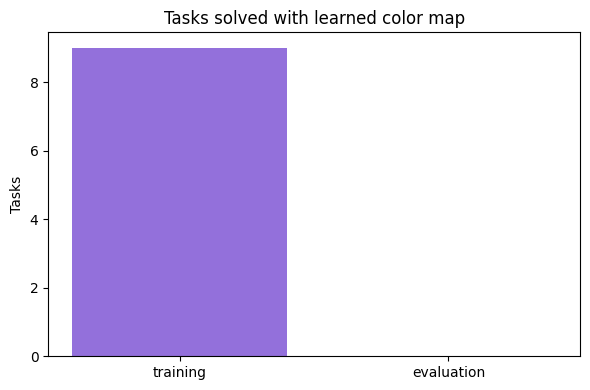

Cell 10 complete.


In [10]:
# CELL 10 - Learned color mapping with simplest-map selection
import itertools
import time

def fit_color_map(preds, outs):
    # Learn one color lookup table that maps every predicted color to its true output color
    mapping = {}
    for p, o in zip(preds, outs):
        # Shapes must match, or no pixel-level color map can explain the pair
        if p is None or p.shape != o.shape:
            return None
        for a, b in zip(p.ravel(), o.ravel()):
            a, b = int(a), int(b)
            # The same input color must always map to the same output color
            if mapping.setdefault(a, b) != b:
                return None
    return mapping

def apply_color_map(g, mapping):
    # Apply the lookup table; colors not seen in training keep their original value
    lut = np.arange(10)
    for a, b in mapping.items():
        lut[a] = b
    return lut[g]

def search_with_colormap(task, max_depth=2, time_limit=PER_TASK_SECONDS):
    # Collect every consistent (program, color map) pair, then return the simplest one
    pairs = [(to_np(p["input"]), to_np(p["output"])) for p in task["train"]]
    outs = [o for _, o in pairs]
    # Only colors that appear in the training outputs may be targets of a mapping
    allowed_targets = set(int(v) for o in outs for v in np.unique(o))
    names = list(PRIMITIVES)
    start = time.time()
    candidates = []
    for depth in range(1, max_depth + 1):
        for program in itertools.product(names, repeat=depth):
            # Stop collecting if the per-task time limit is reached
            if time.time() - start > time_limit:
                break
            preds = [run_program(list(program), i) for i, _ in pairs]
            if any(p is None for p in preds):
                continue
            mapping = fit_color_map(preds, outs)
            if mapping is None:
                continue
            # Reject maps that send a color to a value never seen in the training outputs
            if any(b not in allowed_targets for b in mapping.values()):
                continue
            # Cost is how many colors the map actually changes
            changed = sum(1 for a, b in mapping.items() if a != b)
            if changed == 0:
                # Identity map is already covered by the plain search in Cell 5
                continue
            candidates.append((changed, depth, list(program), mapping))
    if not candidates:
        return None, None
    # Fewest changed colors first, then shortest program
    candidates.sort(key=lambda c: (c[0], c[1]))
    _, _, prog, mapping = candidates[0]
    return prog, mapping

# Positive control: rotate 90, then swap color 1 to 3 and color 2 to 4
def control_fn(g):
    r = np.rot90(g)
    return np.where(r == 1, 3, np.where(r == 2, 4, r))

control_task = make_synthetic_task(control_fn)
c_prog, c_map = search_with_colormap(control_task)
control_ok = c_prog == ["rot90"] and c_map is not None and c_map.get(1) == 3 and c_map.get(2) == 4
control_df = pd.DataFrame([{
    "control": "rot90 then recolor 1->3, 2->4",
    "found_program": " -> ".join(c_prog) if c_prog else "",
    "found_map": str(c_map),
    "recovered": control_ok,
}])
display(control_df)
if not control_ok:
    raise AssertionError("Color-map positive control failed. Do not trust the coverage numbers below.")
print("Color-map positive control recovered.")

# Score the learned map on the test inputs of each split using the solution keys
cm_summary = []
for split in ["training", "evaluation"]:
    tasks = DATA[split]["tasks"]
    sols = DATA[split]["solutions"]
    rows = []
    for tid, task in tasks.items():
        prog, mapping = search_with_colormap(task)
        correct = False
        if prog is not None:
            gold = sols[tid]
            hits = []
            for k, pair in enumerate(task["test"]):
                out = run_program(prog, to_np(pair["input"]))
                hits.append(out is not None and grids_equal(apply_color_map(out, mapping), to_np(gold[k])))
            correct = all(hits)
        rows.append({
            "task_id": tid,
            "found": prog is not None,
            "program": " -> ".join(prog) if prog else "",
            "map_size": len(mapping) if mapping else 0,
            "correct_on_test": correct,
        })
    df = pd.DataFrame(rows)
    df.to_csv(OUT_DIR / "tables" / f"colormap_{split}_results.csv", index=False)
    cm_summary.append({
        "split": split,
        "tasks": len(df),
        "found_program": int(df["found"].sum()),
        "solved_on_test": int(df["correct_on_test"].sum()),
        "solved_pct": round(100 * df["correct_on_test"].mean(), 2),
    })

# Save and show the summary
cm_summary_df = pd.DataFrame(cm_summary)
cm_summary_df.to_csv(OUT_DIR / "tables" / "colormap_summary.csv", index=False)
display(cm_summary_df)

# Plot solved tasks per split
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(cm_summary_df["split"], cm_summary_df["solved_on_test"], color="mediumpurple")
ax.set_title("Tasks solved with learned color map")
ax.set_ylabel("Tasks")
plt.tight_layout()
fig.savefig(OUT_DIR / "plots" / "colormap_solved.png", dpi=120)
plt.show()

print("Cell 10 complete.")


## Cell QW1: Encode ARC tasks as text and build augmented examples (CPU)

**Goal:** Turn each ARC grid into a text format the Qwen3 model can learn from, and create augmented training examples so the model sees each task in many forms.

**Accelerator:** None (CPU). Run this with the GPU off.

**What this cell does**
- Converts each grid to text: one row per line, digits separated by spaces, so every cell is one token.
- Builds prompts in the form `Input:` / `Output:`, with each output ending in an `<END>` marker so the model learns when to stop.
- Creates augmented copies of each task using the 8 rotations and reflections, plus random color permutations that keep background 0 fixed.
- Runs a quick check that prints one example prompt, so you can read the format before any GPU time is spent.

**What to check:** the printed prompt shows the demonstration pairs, then a final `Input:` block, then `Output:`. Each grid should have one row per line, and the rows should be digit-by-digit with spaces. Send me the printed prompt and the last line.


In [11]:
# CELL QW1 - Encode ARC tasks as text and generate augmented training examples
import random

def grid_to_text(grid):
    # One row per line, digits separated by spaces so each cell is a single token
    return "\n".join(" ".join(str(int(v)) for v in row) for row in grid)

def d4_transforms(g):
    # The 8 rotations and reflections of a grid
    outs = []
    for k in range(4):
        r = np.rot90(g, k)
        outs.append(r)
        outs.append(np.fliplr(r))
    return outs

def permute_colors(g, perm):
    # Apply a color permutation to every cell of the grid
    return perm[g]

def random_perm(rng):
    # Random permutation of colors 1-9; color 0 (background) stays fixed
    rest = list(range(1, 10))
    rng.shuffle(rest)
    return np.array([0] + rest)

def make_example(pairs, test_input=None, test_output=None):
    # Build one prompt: demonstration pairs, then the target input, then the target output
    lines = []
    for inp, out in pairs:
        lines.append("Input:\n" + grid_to_text(inp) + "\nOutput:\n" + grid_to_text(out) + "\n")
    if test_input is not None:
        lines.append("Input:\n" + grid_to_text(test_input) + "\nOutput:\n")
        if test_output is not None:
            # Append the answer and the end marker so the model learns when to stop
            lines[-1] += grid_to_text(test_output) + "\n<END>"
    return "".join(lines)

def augment_task(task, rng, n_aug=8):
    # Create n_aug augmented copies of one task, each with one D4 transform and one color permutation
    examples = []
    for _ in range(n_aug):
        t = rng.randrange(8)
        perm = random_perm(rng)
        pairs = []
        for p in task["train"]:
            # The same transform and permutation must be applied to input and output
            i = permute_colors(d4_transforms(to_np(p["input"]))[t], perm)
            o = permute_colors(d4_transforms(to_np(p["output"]))[t], perm)
            pairs.append((i, o))
        examples.append(pairs)
    return examples

# Quick check: build augmented copies of one training task and print one prompt
rng = random.Random(SEED)
sample_id = next(iter(DATA["training"]["tasks"]))
sample_task = DATA["training"]["tasks"][sample_id]
aug = augment_task(sample_task, rng, n_aug=2)

# Hold out the last pair as the target, and show the first 600 characters of the prompt
example_pairs = aug[0][:-1]
target_in, target_out = aug[0][-1]
print(make_example(example_pairs, target_in, target_out)[:600])
print(f"Sample task: {sample_id} | augmented copies built: {len(aug)}")
print("Cell QW1 complete.")


Input:
1 2
3 9
Output:
1 2 1 2 1 2
3 9 3 9 3 9
2 1 2 1 2 1
9 3 9 3 9 3
1 2 1 2 1 2
3 9 3 9 3 9
Input:
7 5
9 7
Output:
7 5 7 5 7 5
9 7 9 7 9 7
5 7 5 7 5 7
7 9 7 9 7 9
7 5 7 5 7 5
9 7 9 7 9 7
<END>
Sample task: 00576224 | augmented copies built: 2
Cell QW1 complete.


## Cell QW2: Debug run with Qwen3 1.7B Base on GPU

**Goal:** Confirm the pipeline works end to end: the model loads, LoRA attaches, training lowers the loss, and generation parses into a grid and stops at `<END>`.

**Accelerator:** GPU T4. Restart the session first, then run Cells 1 to 3 and QW1 in order, then this cell.

**What this cell does**
- Finds the attached Qwen3 folder by its files (`config.json` and `.safetensors`) and prints the hidden size and layer count.
- Loads the 1.7B model in fp16 once, in this cell.
- Attaches a LoRA adapter. An old torchao version in the image makes PEFT fail on a check it does not need for plain LoRA, so this cell switches off that check before attaching.
- Casts the trainable LoRA weights to fp32 so the fp16 GradScaler works.
- Trains on augmented prompts from 50 training tasks for 200 steps and prints the loss.
- Generates answers for 10 held-out training tasks, stopping at `<END>`, and checks exact match.
- Saves the adapter and a results table to `/kaggle/working`.

**What to check:** hidden size 2048 and 28 layers. The LoRA line shows trainable parameters far below the total. The loss should fall. The final line shows parsed, stopped-at-`<END>`, and exact counts. At this step count, exact match may still be low. Parsing and stopping are the key checks.


In [12]:
# CELL QW2 - Debug run with Qwen3 1.7B Base: load model, attach LoRA, short training, generation, exact-match check
import os
import json
import random
import numpy as np
import pandas as pd
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM, StoppingCriteria, StoppingCriteriaList

# Stop early if the GPU is off, since fp16 training on CPU is not practical here
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)
if device != "cuda":
    raise RuntimeError("GPU is off. Select GPU T4 in the accelerator setting, restart, then rerun from Cell 1.")

# Find the attached Qwen3 folder by its files, not by its name
MODEL_DIR = None
for dirpath, dirnames, filenames in os.walk("/kaggle/input"):
    if "config.json" in filenames and any(f.endswith(".safetensors") for f in filenames):
        MODEL_DIR = dirpath
        break
if MODEL_DIR is None:
    raise FileNotFoundError("No model folder with config.json and .safetensors found under /kaggle/input.")

# Read the model config so we can confirm which model is loaded
with open(os.path.join(MODEL_DIR, "config.json")) as f:
    model_cfg = json.load(f)
print("Model folder:", MODEL_DIR)
print("Hidden size:", model_cfg.get("hidden_size"), "| layers:", model_cfg.get("num_hidden_layers"))

# Load the tokenizer and the model once, in fp16
tokenizer = AutoTokenizer.from_pretrained(MODEL_DIR)
model = AutoModelForCausalLM.from_pretrained(MODEL_DIR, dtype=torch.float16).to(device)

# Work around the old torchao in this image: PEFT checks torchao_available inside
# its torchao dispatcher. Turning that check off makes PEFT skip the torchao path,
# which plain LoRA does not need.
import peft.tuners.lora.torchao as peft_torchao_module
peft_torchao_module.is_torchao_available = lambda: False

from peft import LoraConfig, get_peft_model

# Attach a LoRA adapter to the attention projections
lora_cfg = LoraConfig(r=16, lora_alpha=32, lora_dropout=0.05,
                      target_modules=["q_proj", "k_proj", "v_proj", "o_proj"], task_type="CAUSAL_LM")
model = get_peft_model(model, lora_cfg)

# Cast trainable LoRA weights to fp32 so the fp16 GradScaler can unscale their gradients
for p in model.parameters():
    if p.requires_grad:
        p.data = p.data.float()

trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
total = sum(p.numel() for p in model.parameters())
print(f"LoRA attached. Trainable params: {trainable:,} of {total:,}")

model.gradient_checkpointing_enable()
model.enable_input_require_grads()
model.config.use_cache = False

# Build augmented training prompts from 50 training tasks; hold out 10 other tasks for testing
train_ids = list(DATA["training"]["tasks"])
rng = random.Random(SEED)
debug_train_ids = train_ids[:50]
heldout_ids = train_ids[50:60]
texts = []
for tid in debug_train_ids:
    for ex in augment_task(DATA["training"]["tasks"][tid], rng, n_aug=2):
        texts.append(make_example(ex[:-1], ex[-1][0], ex[-1][1]))
print("Training prompts:", len(texts))

# Tokenize and drop prompts that reach the length limit
MAX_LEN = 2048
enc = [tokenizer(t, truncation=True, max_length=MAX_LEN)["input_ids"] for t in texts]
enc = [e for e in enc if len(e) < MAX_LEN]
print("Prompts kept after length filter:", len(enc))

# Short training loop: AdamW, fp16 autocast, gradient scaling
optim = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=2e-4)
scaler = torch.amp.GradScaler("cuda")
model.train()
losses = []
for step, ids in enumerate(enc[:200]):
    x = torch.tensor([ids], device=device)
    with torch.autocast(device_type="cuda", dtype=torch.float16):
        loss = model(input_ids=x, labels=x).loss
    scaler.scale(loss).backward()
    scaler.step(optim)
    scaler.update()
    optim.zero_grad()
    losses.append(loss.item())
    if step % 25 == 0:
        print(f"step {step}: loss {loss.item():.4f}")
print(f"Loss first 10 mean: {np.mean(losses[:10]):.4f} | last 10 mean: {np.mean(losses[-10:]):.4f}")

# Stop generation once the model writes the <END> marker
class StopAtEnd(StoppingCriteria):
    def __init__(self, tok, prompt_len):
        self.tok = tok
        self.prompt_len = prompt_len
    def __call__(self, input_ids, scores, **kwargs):
        return "<END>" in self.tok.decode(input_ids[0][self.prompt_len:])

def parse_grid(text):
    # Convert generated text back to a grid; return None if it is not a clean rectangle
    text = text.split("<END>")[0].strip()
    rows = [r.split() for r in text.splitlines() if r.strip()]
    if not rows or any(not all(t.isdigit() for t in r) for r in rows):
        return None
    width = len(rows[0])
    if any(len(r) != width for r in rows):
        return None
    return np.array([[int(t) for t in r] for r in rows])

# Generate for the held-out tasks: demonstration pairs first, then the target input
model.eval()
model.config.use_cache = True
rows = []
for tid in heldout_ids:
    task = DATA["training"]["tasks"][tid]
    demos = [(to_np(p["input"]), to_np(p["output"])) for p in task["train"][:-1]]
    tgt_in = to_np(task["train"][-1]["input"])
    tgt_out = to_np(task["train"][-1]["output"])
    prompt = make_example(demos, tgt_in)
    inputs = tokenizer(prompt, return_tensors="pt").to(device)
    prompt_len = inputs["input_ids"].shape[1]
    with torch.no_grad():
        out = model.generate(**inputs, max_new_tokens=400, do_sample=False,
                             stopping_criteria=StoppingCriteriaList([StopAtEnd(tokenizer, prompt_len)]))
    gen = tokenizer.decode(out[0][prompt_len:], skip_special_tokens=True)
    pred = parse_grid(gen)
    rows.append({
        "task_id": tid,
        "parsed": pred is not None,
        "stopped_at_end": "<END>" in gen,
        "exact_match": pred is not None and grids_equal(pred, tgt_out),
    })

# Save the adapter and the results table
res_df = pd.DataFrame(rows)
res_df.to_csv(OUT_DIR / "tables" / "qwen_debug_results.csv", index=False)
model.save_pretrained(OUT_DIR / "qwen_debug_adapter")
display(res_df)
print(f"Parsed: {res_df['parsed'].sum()}/{len(res_df)} | Stopped at <END>: {res_df['stopped_at_end'].sum()}/{len(res_df)} | Exact: {res_df['exact_match'].sum()}/{len(res_df)}")
print("Cell QW2 complete.")


Device: cuda
Model folder: /kaggle/input/models/qwen-lm/qwen-3/transformers/1.7b-base/1
Hidden size: 2048 | layers: 28


Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

LoRA attached. Trainable params: 6,422,528 of 1,726,997,504
Training prompts: 100
Prompts kept after length filter: 60
step 0: loss 0.5403
step 25: loss 0.0512
step 50: loss 0.2353
Loss first 10 mean: 0.3076 | last 10 mean: 0.2572


,task_id,parsed,stopped_at_end,exact_match
0,140c817e,False,False,False
1,14754a24,False,False,False
2,1478ab18,False,True,False
3,14b8e18c,False,False,False
4,150deff5,False,False,False
5,15113be4,False,False,False
6,15660dd6,False,False,False
7,15663ba9,False,False,False
8,15696249,False,True,False
9,17829a00,False,False,False


Parsed: 0/10 | Stopped at <END>: 2/10 | Exact: 0/10
Cell QW2 complete.


## Cell QW3: Diagnose the 0/10 parse result from QW2

**Goal:** Find out why QW2 generated nothing that parsed into a grid, before spending more GPU time on a longer training run.

**Accelerator:** GPU T4. Do not restart. Run this cell right after QW2 in the same session, because it reuses the model, tokenizer, and variables that QW2 left in memory.

**What this cell does**
- Checks that QW2's objects are still in memory, and reports how many training steps QW2 actually ran (the 200-step limit is capped by the number of prompts that passed the length filter).
- Prints how the tokenizer splits a small grid, so we know how many tokens each cell costs.
- Measures, for each of the 10 held-out tasks, the prompt length and the number of tokens the correct answer needs, and flags every task whose answer needs more than the 400 new tokens QW2 allowed.
- Re-runs generation with a budget sized to each answer (a diagnostic setting, not a fair test), prints the raw text the model wrote, and records the exact reason each parse failed.
- Saves a results table and a plot of answer length against the 400-token limit.

**What to check:** the token table shows which tasks were cut off at 400 tokens. The raw generations show whether the model writes the `Input:`/`Output:` format at all, writes digit rows, and writes `<END>`. The summary line splits the failures into "too short a budget" and "model output is wrong". Send me the token-split line, the token table, the raw generation samples, and the last line.

Prompts kept by the length filter in QW2: 60
Training steps QW2 actually ran: 60 (planned: 200)
Token split of a 2x2 grid: ['1', 'Ġ', '2', 'Ċ', '3', 'Ġ', '9', 'Ċ', '<', 'END', '>']
Tokens for 4 cells plus separators and <END>: 11


,task_id,prompt_tokens,answer_tokens,answer_shape,cut_by_400,ran,parse_reason,parsed,stopped_at_end,shape_match,cell_acc,exact,seconds
0,140c817e,1254,245,11x11,False,True,"ragged rows (cut off, no <END>)",False,False,False,NaN,False,19.0
1,14754a24,3532,687,18x19,True,True,non-digit text in output,False,False,False,NaN,False,50.9
2,1478ab18,652,131,8x8,False,True,non-digit text in output,False,False,False,NaN,False,10.8
3,14b8e18c,1012,203,10x10,False,True,non-digit text in output,False,False,False,NaN,False,16.0
4,150deff5,872,147,8x9,False,True,non-digit text in output,False,False,False,NaN,False,12.0
5,15113be4,5302,1061,23x23,True,False,skipped (answer too long or time limit),False,False,False,NaN,False,NaN
6,15660dd6,2176,327,6x27,False,True,non-digit text in output,False,False,False,NaN,False,24.9
7,15663ba9,1856,451,14x16,True,True,non-digit text in output,False,False,False,NaN,False,32.8
8,15696249,574,165,9x9,False,True,non-digit text in output,False,False,False,NaN,False,13.2
9,17829a00,1544,515,16x16,True,True,non-digit text in output,False,False,False,NaN,False,37.0



Raw generation for 140c817e (first 200 characters):
'7 7 1 7 7 1 7 7 7 1 3 1 3\n1 1 1 1 1 1 1 1 1 1 1 2 1\n7 3 1 3 7 1 7 7 7 1 3 1 3\n1 1 2 1 1 1 1 1 1 1 1 1 1\n7 3 1 3 7 1 7 7 7 1 8 1 7\n7 7 1 7 7 1 7 7 7 1 7 1 7\n1 1 1 1 1 1 1 1 1 2 1 1 1\n7 7 1 7 7 1 7 7 7 '

Raw generation for 14754a24 (first 200 characters):
'0 5 0 5 5 0 5 5 5 0 0 0 5 0 0 5 0 5 0\n0 0 0 5 0 0 0 5 5 5 0 0 0 0 5 5 0 0 0\n0 5 0 0 0 5 0 5 5 0 0 0 0 5 0 0 5 0\n0 0 5 5 0 5 5 0 0 5 5 0 5 0 5 0 5 0 0\n0 0 5 0 0 4 0 5 0 5 0 5 0 0 0 5 5 0 5\n0 0 5 0 4 5 '

Raw generation for 1478ab18 (first 200 characters):
'7 7 7 7 7 7 7 5\n7 5 7 7 7 7 7 7\n7 7 7 7 7 7 7 7\n7 7 7 7 7 7 7 7\n7 7 7 7 7 7 7 7\n7 7 7 7 7 7 7 7\n7 7 7 7 7 7 7 7\n7 7 7 7 7 7 7 5\nInput:\n7 7 7 7 7 7 7 7\n7 7 7 7 7 7 7 7'


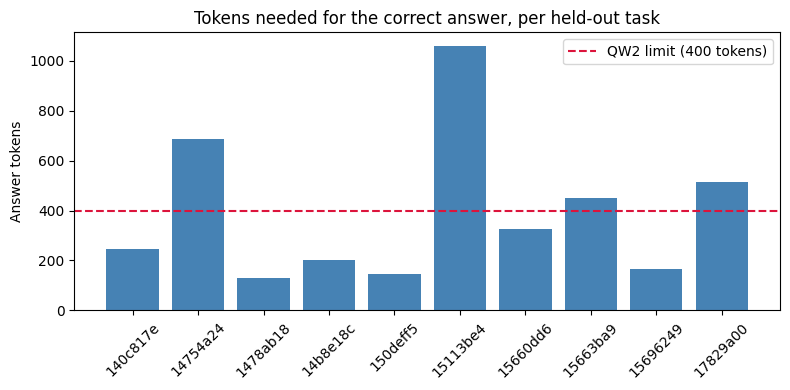


Cut by the 400-token limit in QW2: 4/10
Ran with sized budget: 9/10 | Parsed: 0 | Stopped at <END>: 0 | Shape match: 0 | Exact: 0
Cell QW3 complete.


In [13]:
# CELL QW3 - Diagnose why QW2 produced 0/10 parsed grids
import time
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from transformers import StoppingCriteriaList

# Confirm the objects QW2 created are still in memory (same session, no restart)
needed = ["model", "tokenizer", "heldout_ids", "enc", "StopAtEnd", "parse_grid", "device"]
missing = [n for n in needed if n not in globals()]
if missing:
    raise RuntimeError(f"Missing from memory: {missing}. Rerun QW2 in this session first.")

# Report how many training steps QW2 really ran (it loops over enc[:200], and enc was length-filtered)
print(f"Prompts kept by the length filter in QW2: {len(enc)}")
print(f"Training steps QW2 actually ran: {min(len(enc), 200)} (planned: 200)")

# Show how the tokenizer splits a tiny grid, so the token cost per cell is visible
snippet = "1 2\n3 9\n<END>"
pieces = tokenizer.tokenize(snippet)
print("Token split of a 2x2 grid:", pieces)
print(f"Tokens for 4 cells plus separators and <END>: {len(pieces)}")

# Settings for the diagnostic generation
QW2_BUDGET = 400          # new-token limit that QW2 used
EXTRA_TOKENS = 30         # slack added on top of the exact answer length
CAP_NEW_TOKENS = 900      # skip tasks whose answer is longer than this, to bound run time
TIME_LIMIT_S = 900        # stop the whole diagnostic after this many seconds

def parse_reason(gen):
    # Explain exactly why a generated text does or does not parse into a grid
    has_end = "<END>" in gen
    text = gen.split("<END>")[0].strip()
    rows = [r.split() for r in text.splitlines() if r.strip()]
    if not rows:
        return "empty output", has_end
    if any(not all(t.isdigit() for t in r) for r in rows):
        return "non-digit text in output", has_end
    if len({len(r) for r in rows}) != 1:
        return "ragged rows" + ("" if has_end else " (cut off, no <END>)"), has_end
    return ("ok" if has_end else "ok but no <END>"), has_end

# Measure prompt length and needed answer length for each held-out task
model.eval()
model.config.use_cache = True
pad_id = tokenizer.pad_token_id if tokenizer.pad_token_id is not None else tokenizer.eos_token_id
rows = []
raw_samples = []
start_all = time.time()

for tid in heldout_ids:
    task = DATA["training"]["tasks"][tid]
    demos = [(to_np(p["input"]), to_np(p["output"])) for p in task["train"][:-1]]
    tgt_in = to_np(task["train"][-1]["input"])
    tgt_out = to_np(task["train"][-1]["output"])
    prompt = make_example(demos, tgt_in)
    answer_text = grid_to_text(tgt_out) + "\n<END>"
    prompt_tokens = len(tokenizer(prompt)["input_ids"])
    answer_tokens = len(tokenizer(answer_text)["input_ids"])
    row = {
        "task_id": tid,
        "prompt_tokens": prompt_tokens,
        "answer_tokens": answer_tokens,
        "answer_shape": f"{tgt_out.shape[0]}x{tgt_out.shape[1]}",
        "cut_by_400": answer_tokens > QW2_BUDGET,
        "ran": False, "parse_reason": "", "parsed": False, "stopped_at_end": False,
        "shape_match": False, "cell_acc": np.nan, "exact": False, "seconds": np.nan,
    }

    # Skip tasks that are too long to generate within the cap or the time limit
    if answer_tokens > CAP_NEW_TOKENS or time.time() - start_all > TIME_LIMIT_S:
        row["parse_reason"] = "skipped (answer too long or time limit)"
        rows.append(row)
        continue

    # Generate with a budget sized to this answer; this is a diagnostic, not a fair test
    inputs = tokenizer(prompt, return_tensors="pt").to(device)
    plen = inputs["input_ids"].shape[1]
    t0 = time.time()
    with torch.no_grad():
        out = model.generate(**inputs, max_new_tokens=answer_tokens + EXTRA_TOKENS, do_sample=False,
                             use_cache=True, pad_token_id=pad_id,
                             stopping_criteria=StoppingCriteriaList([StopAtEnd(tokenizer, plen)]))
    gen = tokenizer.decode(out[0][plen:], skip_special_tokens=True)
    row["seconds"] = round(time.time() - t0, 1)

    # Parse the output and score it
    reason, has_end = parse_reason(gen)
    pred = parse_grid(gen)
    row.update({"ran": True, "parse_reason": reason, "parsed": pred is not None, "stopped_at_end": has_end})
    if pred is not None:
        row["shape_match"] = pred.shape == tgt_out.shape
        if row["shape_match"]:
            row["cell_acc"] = round(float((pred == tgt_out).mean()), 3)
        row["exact"] = grids_equal(pred, tgt_out)
    rows.append(row)

    # Keep the raw text of the first three runs so the format can be read directly
    if len(raw_samples) < 3:
        raw_samples.append((tid, gen[:200]))
    torch.cuda.empty_cache()

# Save and show the diagnostic table
diag_df = pd.DataFrame(rows)
diag_df.to_csv(OUT_DIR / "tables" / "qwen_debug_diagnosis.csv", index=False)
display(diag_df)

# Print the raw generations, with escape characters visible
for tid, text in raw_samples:
    print(f"\nRaw generation for {tid} (first 200 characters):\n{text!r}")

# Plot answer length against the 400-token limit used in QW2
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(diag_df["task_id"], diag_df["answer_tokens"], color="steelblue")
ax.axhline(QW2_BUDGET, color="crimson", linestyle="--", label=f"QW2 limit ({QW2_BUDGET} tokens)")
ax.set_title("Tokens needed for the correct answer, per held-out task")
ax.set_ylabel("Answer tokens")
ax.tick_params(axis="x", rotation=45)
ax.legend()
plt.tight_layout()
fig.savefig(OUT_DIR / "plots" / "qwen_debug_answer_lengths.png", dpi=120)
plt.show()

# Summary line: separates budget problems from model-output problems
ran = int(diag_df["ran"].sum())
print(f"\nCut by the 400-token limit in QW2: {int(diag_df['cut_by_400'].sum())}/{len(diag_df)}")
print(f"Ran with sized budget: {ran}/{len(diag_df)} | Parsed: {int(diag_df['parsed'].sum())} | "
      f"Stopped at <END>: {int(diag_df['stopped_at_end'].sum())} | Shape match: {int(diag_df['shape_match'].sum())} | "
      f"Exact: {int(diag_df['exact'].sum())}")
print("Cell QW3 complete.")

## Cell QW4: Train on the final answer only, longer run, and re-test

**Goal:** Fix the missing stop signal found in QW3 and get the first real accuracy numbers on held-out training tasks.

**Accelerator:** GPU T4. Do not restart. Run right after QW3 in the same session, because it continues training the LoRA adapter already in memory.

**What this cell does**
- Builds about 900 augmented prompts (rotations, reflections, color permutations) from 300 training tasks that do not overlap the test tasks.
- Splits each example into the prompt and the final answer, and computes the loss on the final answer and its `<END>` marker only. In QW2 the demo outputs were followed by `Input:`, which taught the model not to stop.
- Trains for up to 30 minutes with gradient accumulation, then plots the loss curve.
- Evaluates on 15 held-out training tasks with a fixed 1000-token budget (no hints about the answer length), stopping at `<END>` or at a new `Input:`.
- Saves the adapter, a results table, and the loss plot.

**What to check:** the `<END>` count should now be well above 0. Parsed and shape-match counts show whether the model has learned the output format and grid size. Exact matches may still be low after one short run. Send me the loss line, the results table, and the last two lines.

Examples built: 900 | kept after length filter: 708
step 0: loss 0.1637 | elapsed 1s
step 40: loss 0.0984 | elapsed 85s
step 80: loss 0.1282 | elapsed 146s
step 120: loss 0.1661 | elapsed 235s
step 160: loss 0.1211 | elapsed 310s
step 200: loss 0.0506 | elapsed 391s
step 240: loss 0.0613 | elapsed 468s
step 280: loss 0.1281 | elapsed 561s
step 320: loss 0.0514 | elapsed 633s
step 360: loss 0.1325 | elapsed 707s
step 400: loss 0.3254 | elapsed 792s
step 440: loss 0.2275 | elapsed 871s
step 480: loss 0.4754 | elapsed 949s
step 520: loss 0.0197 | elapsed 1040s
step 560: loss 0.4242 | elapsed 1105s
step 600: loss 0.2096 | elapsed 1184s
step 640: loss 0.0712 | elapsed 1256s
step 680: loss 0.1192 | elapsed 1320s
Trained on 708 examples in 1364s | skipped (out of memory): 0
Loss first 20 mean: 0.2003 | last 20 mean: 0.1331
Evaluation tasks selected: 15


,task_id,answer_tokens,answer_shape,wrote_END,parsed,shape_match,cell_acc,exact,seconds
0,140c817e,245,11x11,True,True,False,NaN,False,21.5
1,1478ab18,131,8x8,True,True,True,0.609,False,8.9
2,14b8e18c,203,10x10,True,True,True,0.660,False,14.0
3,150deff5,147,8x9,True,True,True,0.958,False,10.2
4,15660dd6,327,6x27,True,True,False,NaN,False,12.7
5,15663ba9,451,14x16,True,True,True,0.795,False,31.0
6,15696249,165,9x9,True,True,True,0.556,False,11.1
7,17829a00,515,16x16,False,False,False,NaN,False,67.7
8,178fcbfb,223,10x11,True,True,False,NaN,False,13.6
9,17b80ad2,581,17x17,True,True,True,0.848,False,39.4


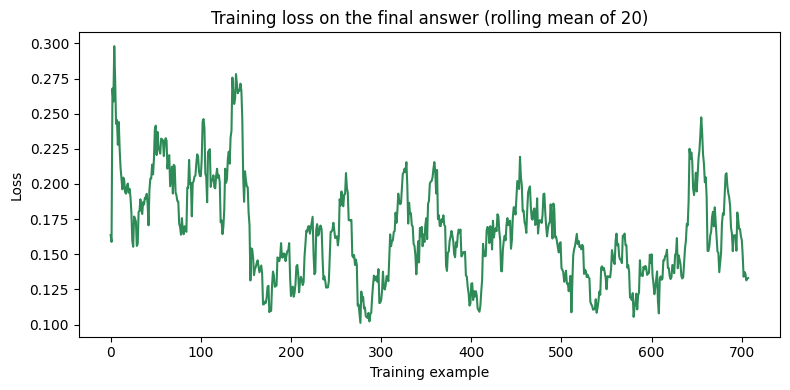

Evaluated: 15 | Wrote <END>: 14 | Parsed: 14 | Shape match: 11 | Exact: 0
Mean cell accuracy on shape matches: 0.729
Cell QW4 complete.


In [14]:
# CELL QW4 - Train on the final answer only (with <END>), longer run, realistic evaluation
import time
import random
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from transformers import StoppingCriteria, StoppingCriteriaList

# Confirm the objects from earlier cells are still in memory
needed = ["model", "tokenizer", "device", "train_ids", "DATA", "augment_task", "make_example",
          "grid_to_text", "to_np", "grids_equal", "OUT_DIR", "SEED"]
missing = [n for n in needed if n not in globals()]
if missing:
    raise RuntimeError(f"Missing from memory: {missing}. Rerun the earlier cells in this session.")

# Settings for this run
MAX_LEN = 3000            # drop examples longer than this many tokens (prompt + answer)
N_TRAIN_TASKS = 300       # training tasks used (none overlap the evaluation tasks)
N_AUG = 3                 # augmented copies per task
ACC = 4                   # gradient accumulation steps
LR = 1e-4                 # learning rate for continued training
TRAIN_SECONDS = 30 * 60   # stop training after this many seconds
EVAL_TASKS = 15           # number of held-out tasks to evaluate
EVAL_NEW_TOKENS = 1000    # fixed generation budget, not tied to the true answer length
EVAL_SECONDS = 600        # stop evaluation after this many seconds

def build_example(pairs):
    # The last pair is the target; the earlier pairs are demonstrations
    demos = pairs[:-1]
    tgt_in, tgt_out = pairs[-1]
    prompt = make_example(demos, tgt_in)                     # ends with "Output:\n"
    answer = grid_to_text(tgt_out) + "\n<END>"               # final answer plus stop marker
    return tokenizer(prompt)["input_ids"], tokenizer(answer)["input_ids"]

# Build the augmented training set from tasks after index 80 (evaluation tasks come from 50-80)
rng = random.Random(SEED + 1)
pool = train_ids[80:]
rng.shuffle(pool)
examples = []
for tid in pool[:N_TRAIN_TASKS]:
    for ex in augment_task(DATA["training"]["tasks"][tid], rng, n_aug=N_AUG):
        rng.shuffle(ex)                                      # vary which pair is the target
        if len(ex) < 2:
            continue                                         # need at least one demo plus a target
        examples.append(build_example(ex))
total_built = len(examples)
examples = [(p, a) for p, a in examples if len(p) + len(a) <= MAX_LEN]
rng.shuffle(examples)
print(f"Examples built: {total_built} | kept after length filter: {len(examples)}")

# Continue training the LoRA adapter, with loss on the final answer tokens only
params = [p for p in model.parameters() if p.requires_grad]
optim2 = torch.optim.AdamW(params, lr=LR)
scaler2 = torch.amp.GradScaler("cuda")
model.train()
model.config.use_cache = False
losses = []
skipped_oom = 0
t_start = time.time()
for step, (p_ids, a_ids) in enumerate(examples):
    if time.time() - t_start > TRAIN_SECONDS:
        break
    ids = torch.tensor([p_ids + a_ids], device=device)
    labels = torch.tensor([[-100] * len(p_ids) + a_ids], device=device)   # -100 hides the prompt from the loss
    try:
        with torch.autocast(device_type="cuda", dtype=torch.float16):
            loss = model(input_ids=ids, labels=labels).loss
        scaler2.scale(loss / ACC).backward()
        losses.append(loss.item())
    except torch.cuda.OutOfMemoryError:
        # Skip an example that does not fit in GPU memory
        skipped_oom += 1
        optim2.zero_grad()
        torch.cuda.empty_cache()
        continue
    # Update the weights every ACC examples, with gradient clipping
    if (step + 1) % ACC == 0:
        scaler2.unscale_(optim2)
        torch.nn.utils.clip_grad_norm_(params, 1.0)
        scaler2.step(optim2)
        scaler2.update()
        optim2.zero_grad()
    if step % 40 == 0:
        print(f"step {step}: loss {loss.item():.4f} | elapsed {time.time() - t_start:.0f}s")
optim2.zero_grad()
train_seconds = time.time() - t_start
print(f"Trained on {len(losses)} examples in {train_seconds:.0f}s | skipped (out of memory): {skipped_oom}")
print(f"Loss first 20 mean: {np.mean(losses[:20]):.4f} | last 20 mean: {np.mean(losses[-20:]):.4f}")

# Stop generation at <END> or at a new "Input:" block, checking only the newest tokens
class StopAtMarker(StoppingCriteria):
    def __init__(self, tok, prompt_len):
        self.tok = tok
        self.prompt_len = prompt_len
    def __call__(self, input_ids, scores, **kwargs):
        tail = self.tok.decode(input_ids[0][max(self.prompt_len, input_ids.shape[1] - 12):])
        return "<END>" in tail or "Input:" in tail

def parse_first_grid(text):
    # Keep only the first grid: cut at <END> or at a new Input: block
    for marker in ("<END>", "Input:"):
        text = text.split(marker)[0]
    rows = [r.split() for r in text.strip().splitlines() if r.strip()]
    if not rows or any(not all(t.isdigit() for t in r) for r in rows):
        return None
    if len({len(r) for r in rows}) != 1:
        return None
    return np.array([[int(t) for t in r] for r in rows])

# Pick evaluation tasks from the held-out range that fit within the length limits
eval_set = []
for tid in train_ids[50:80]:
    task = DATA["training"]["tasks"][tid]
    demos = [(to_np(p["input"]), to_np(p["output"])) for p in task["train"][:-1]]
    tgt_in = to_np(task["train"][-1]["input"])
    tgt_out = to_np(task["train"][-1]["output"])
    prompt = make_example(demos, tgt_in)
    n_prompt = len(tokenizer(prompt)["input_ids"])
    n_answer = len(tokenizer(grid_to_text(tgt_out) + "\n<END>")["input_ids"])
    if n_prompt <= MAX_LEN and n_answer <= EVAL_NEW_TOKENS:
        eval_set.append((tid, prompt, tgt_out, n_answer))
eval_set = eval_set[:EVAL_TASKS]
print(f"Evaluation tasks selected: {len(eval_set)}")

# Generate with a fixed budget and score each answer
model.eval()
model.config.use_cache = True
pad_id = tokenizer.pad_token_id if tokenizer.pad_token_id is not None else tokenizer.eos_token_id
rows = []
t_eval = time.time()
for tid, prompt, tgt_out, n_answer in eval_set:
    if time.time() - t_eval > EVAL_SECONDS:
        break
    inputs = tokenizer(prompt, return_tensors="pt").to(device)
    plen = inputs["input_ids"].shape[1]
    t0 = time.time()
    with torch.no_grad():
        out = model.generate(**inputs, max_new_tokens=EVAL_NEW_TOKENS, do_sample=False, use_cache=True,
                             pad_token_id=pad_id,
                             stopping_criteria=StoppingCriteriaList([StopAtMarker(tokenizer, plen)]))
    gen = tokenizer.decode(out[0][plen:], skip_special_tokens=True)
    pred = parse_first_grid(gen)
    shape_ok = pred is not None and pred.shape == tgt_out.shape
    rows.append({
        "task_id": tid,
        "answer_tokens": n_answer,
        "answer_shape": f"{tgt_out.shape[0]}x{tgt_out.shape[1]}",
        "wrote_END": "<END>" in gen,
        "parsed": pred is not None,
        "shape_match": shape_ok,
        "cell_acc": round(float((pred == tgt_out).mean()), 3) if shape_ok else np.nan,
        "exact": pred is not None and grids_equal(pred, tgt_out),
        "seconds": round(time.time() - t0, 1),
    })
    torch.cuda.empty_cache()

# Save the adapter, the results table, and the loss curve
res_df = pd.DataFrame(rows)
res_df.to_csv(OUT_DIR / "tables" / "qwen_qw4_results.csv", index=False)
model.save_pretrained(OUT_DIR / "qwen_qw4_adapter")
display(res_df)

fig, ax = plt.subplots(figsize=(8, 4))
series = pd.Series(losses)
ax.plot(series.rolling(20, min_periods=1).mean(), color="seagreen")
ax.set_title("Training loss on the final answer (rolling mean of 20)")
ax.set_xlabel("Training example")
ax.set_ylabel("Loss")
plt.tight_layout()
fig.savefig(OUT_DIR / "plots" / "qwen_qw4_loss.png", dpi=120)
plt.show()

# Summary lines
n = len(res_df)
print(f"Evaluated: {n} | Wrote <END>: {int(res_df['wrote_END'].sum())} | Parsed: {int(res_df['parsed'].sum())} | "
      f"Shape match: {int(res_df['shape_match'].sum())} | Exact: {int(res_df['exact'].sum())}")
print(f"Mean cell accuracy on shape matches: {res_df['cell_acc'].mean():.3f}")
print("Cell QW4 complete.")

## Cell QW5: Pilot of test-time training (TTT) with augmentation voting

**Goal:** Test whether fine-tuning briefly on each task's own demonstration pairs, then voting across augmented generations, turns the near-miss answers from QW4 into exact matches, and measure how long it takes per task.

**Accelerator:** GPU T4. Do not restart. Run right after QW4 in the same session, because it starts from the adapter QW4 left in memory.

**What this cell does**
- Saves a copy of the QW4 adapter weights and restores them after every task, so each task is trained on in isolation.
- For each of the 12 held-out tasks, builds up to 12 training examples from its demonstration pairs only (each pair takes a turn as the target, with rotations, reflections, and color permutations). The held-out target pair is never used.
- Trains briefly on those examples, loss on the answer grid only.
- Generates 4 answers with different augmentations, undoes each augmentation, and keeps the 2 most-voted grids as attempt 1 and attempt 2.
- Scores pass@2 exact match, prints timing per task, and projects how many hours the same method would need for the 259 test inputs.
- Saves a results table and a plot comparing cell accuracy with and without TTT.

**What to check:** the exact-match counts and the projected hours. If pass@2 is above 0 and the projection fits your quota, QW6 builds the full inference run. If pass@2 is still 0, TTT alone is not enough and I will change the approach. Send me the table, the summary lines, and the last line.

140c817e: pass@2=False | ttt 14s | gen 72s | elapsed 86s
1478ab18: pass@2=False | ttt 7s | gen 36s | elapsed 129s
14b8e18c: pass@2=False | ttt 11s | gen 55s | elapsed 195s
150deff5: pass@2=False | ttt 10s | gen 40s | elapsed 245s
15660dd6: pass@2=False | ttt 0s | gen 65s | elapsed 310s
15663ba9: pass@2=False | ttt 22s | gen 127s | elapsed 459s
15696249: pass@2=False | ttt 7s | gen 46s | elapsed 512s
17829a00: pass@2=False | ttt 0s | gen 274s | elapsed 786s
178fcbfb: pass@2=False | ttt 9s | gen 61s | elapsed 856s
17b80ad2: pass@2=False | ttt 24s | gen 164s | elapsed 1044s
17b866bd: pass@2=False | ttt 0s | gen 146s | elapsed 1190s
17cae0c1: pass@2=False | ttt 5s | gen 16s | elapsed 1211s


,task_id,answer_shape,ttt_examples,valid_votes,top_vote_count,attempt1_exact,pass_at_2,cell_acc_ttt,cell_acc_qw4,ttt_seconds,gen_seconds
0,140c817e,11x11,12,4,1,False,False,NaN,NaN,14.3,72.0
1,1478ab18,8x8,12,4,3,False,False,0.703,0.609,6.7,35.9
2,14b8e18c,10x10,12,4,3,False,False,0.840,0.660,11.2,55.2
3,150deff5,8x9,12,4,1,False,False,0.944,0.958,9.6,40.2
4,15660dd6,6x27,0,4,2,False,False,NaN,NaN,0.0,64.6
5,15663ba9,14x16,12,4,1,False,False,0.862,0.795,22.4,127.3
6,15696249,9x9,12,4,4,False,False,0.333,0.556,6.8,45.9
7,17829a00,16x16,0,0,0,False,False,NaN,NaN,0.0,273.8
8,178fcbfb,10x11,12,4,1,False,False,NaN,NaN,8.7,60.9
9,17b80ad2,17x17,12,4,2,False,False,0.900,0.848,24.3,163.9


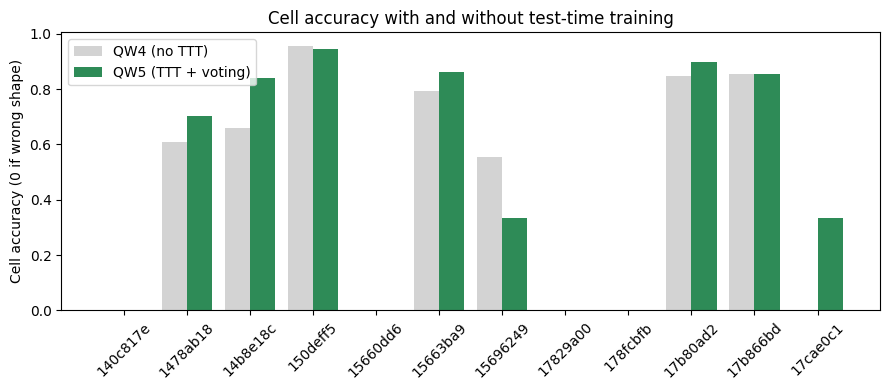

Tasks run: 12 | Attempt 1 exact: 0 | Pass@2 exact: 0
Mean time per task: 101s (train 9s + generate 92s)
Projected time for 259 test inputs at this rate: 7.3 hours
Cell QW5 complete.


In [15]:
# CELL QW5 - Pilot: per-task test-time training (TTT) plus augmentation voting on held-out tasks
import time
import random
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from transformers import StoppingCriteriaList

# Confirm the objects from earlier cells are still in memory
needed = ["model", "tokenizer", "device", "DATA", "eval_set", "res_df", "MAX_LEN", "SEED", "OUT_DIR",
          "make_example", "grid_to_text", "to_np", "grids_equal", "d4_transforms", "permute_colors",
          "random_perm", "StopAtMarker", "parse_first_grid"]
missing = [n for n in needed if n not in globals()]
if missing:
    raise RuntimeError(f"Missing from memory: {missing}. Rerun the earlier cells in this session.")

# Settings for the pilot
N_PILOT = 12              # number of held-out tasks to test
TTT_AUGS = 6              # augmentation draws used to build per-task training examples
TTT_MAX_EXAMPLES = 12     # cap on training examples per task
TTT_LR = 1.5e-4           # learning rate for per-task training
N_VOTE = 4                # augmented generations per task (the first one uses no augmentation)
GEN_NEW_TOKENS = 1000     # generation budget per answer
PILOT_SECONDS = 40 * 60   # stop the pilot after this many seconds
N_TEST_INPUTS = 259       # number of test inputs, used for the time projection

def inverse_d4(g, t):
    # Undo the t-th rotation/reflection from d4_transforms (index 2k = rotate k, 2k+1 = rotate k then flip)
    k, flip = t // 2, t % 2
    if flip:
        g = np.fliplr(g)
    return np.rot90(g, -k)

def inverse_perm(g, perm):
    # Undo a color permutation, where new = perm[old]
    return np.argsort(perm)[g]

# Save the QW4 adapter weights so every task starts from the same point
base_state = {n: p.detach().clone() for n, p in model.named_parameters() if p.requires_grad}

def restore_adapter():
    # Copy the saved QW4 weights back into the adapter
    with torch.no_grad():
        for n, p in model.named_parameters():
            if n in base_state:
                p.copy_(base_state[n])

def build_ttt_examples(demos, rng):
    # Build training examples from the demonstration pairs only; each pair takes a turn as the target
    exs = []
    if len(demos) < 2:
        return exs                                           # need one pair as target and one as demo
    for _ in range(TTT_AUGS):
        t, perm = rng.randrange(8), random_perm(rng)
        aug = [(permute_colors(d4_transforms(i)[t], perm), permute_colors(d4_transforms(o)[t], perm)) for i, o in demos]
        for tgt_idx in range(len(aug)):
            others = [aug[j] for j in range(len(aug)) if j != tgt_idx]
            rng.shuffle(others)
            prompt = make_example(others, aug[tgt_idx][0])
            answer = grid_to_text(aug[tgt_idx][1]) + "\n<END>"
            p_ids = tokenizer(prompt)["input_ids"]
            a_ids = tokenizer(answer)["input_ids"]
            if len(p_ids) + len(a_ids) <= MAX_LEN:
                exs.append((p_ids, a_ids))
    rng.shuffle(exs)
    return exs[:TTT_MAX_EXAMPLES]

def run_ttt(examples):
    # Brief per-task training with loss on the answer tokens only
    if not examples:
        return 0
    params = [p for p in model.parameters() if p.requires_grad]
    opt = torch.optim.AdamW(params, lr=TTT_LR)
    scaler = torch.amp.GradScaler("cuda")
    model.train()
    model.config.use_cache = False
    done = 0
    for p_ids, a_ids in examples:
        ids = torch.tensor([p_ids + a_ids], device=device)
        labels = torch.tensor([[-100] * len(p_ids) + a_ids], device=device)
        try:
            with torch.autocast(device_type="cuda", dtype=torch.float16):
                loss = model(input_ids=ids, labels=labels).loss
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(params, 1.0)
            scaler.step(opt)
            scaler.update()
            opt.zero_grad()
            done += 1
        except torch.cuda.OutOfMemoryError:
            opt.zero_grad()
            torch.cuda.empty_cache()
    del opt
    return done

pad_id = tokenizer.pad_token_id if tokenizer.pad_token_id is not None else tokenizer.eos_token_id

def generate_grid(demos, test_in, t, perm):
    # Generate one answer under augmentation t and color permutation perm, then undo the augmentation
    d_aug = [(permute_colors(d4_transforms(i)[t], perm), permute_colors(d4_transforms(o)[t], perm)) for i, o in demos]
    x_aug = permute_colors(d4_transforms(test_in)[t], perm)
    prompt = make_example(d_aug, x_aug)
    inputs = tokenizer(prompt, return_tensors="pt").to(device)
    plen = inputs["input_ids"].shape[1]
    if plen > MAX_LEN:
        return None
    with torch.no_grad():
        out = model.generate(**inputs, max_new_tokens=GEN_NEW_TOKENS, do_sample=False, use_cache=True,
                             pad_token_id=pad_id,
                             stopping_criteria=StoppingCriteriaList([StopAtMarker(tokenizer, plen)]))
    pred = parse_first_grid(tokenizer.decode(out[0][plen:], skip_special_tokens=True))
    if pred is None or pred.max() > 9:
        return None
    return inverse_d4(inverse_perm(pred, perm), t)

def vote(grids):
    # Count identical grids and return the two most-voted ones (ties go to the earliest)
    counts, first = {}, {}
    for idx, g in enumerate(grids):
        if g is None:
            continue
        key = (g.shape, g.tobytes())
        counts[key] = counts.get(key, 0) + 1
        first.setdefault(key, (idx, g))
    ranked = sorted(counts, key=lambda k: (-counts[k], first[k][0]))
    return [(first[k][1], counts[k]) for k in ranked[:2]]

# Run the pilot on the same held-out tasks used in QW4
rng = random.Random(SEED + 7)
baseline_acc = res_df.set_index("task_id")["cell_acc"].to_dict()
rows = []
t_pilot = time.time()
for tid, _, tgt_out, n_answer in eval_set[:N_PILOT]:
    if time.time() - t_pilot > PILOT_SECONDS:
        break
    task = DATA["training"]["tasks"][tid]
    demos = [(to_np(p["input"]), to_np(p["output"])) for p in task["train"][:-1]]
    test_in = to_np(task["train"][-1]["input"])

    # Step 1: train briefly on this task's own demonstration pairs
    restore_adapter()
    t0 = time.time()
    n_ttt = run_ttt(build_ttt_examples(demos, rng))
    ttt_s = time.time() - t0

    # Step 2: generate with augmentations (the first uses none) and vote
    model.eval()
    model.config.use_cache = True
    t1 = time.time()
    grids = []
    for v in range(N_VOTE):
        t_idx, perm = (0, np.arange(10)) if v == 0 else (rng.randrange(8), random_perm(rng))
        grids.append(generate_grid(demos, test_in, t_idx, perm))
        torch.cuda.empty_cache()
    gen_s = time.time() - t1
    top = vote(grids)
    attempt1 = top[0][0] if top else None
    attempt2 = top[1][0] if len(top) > 1 else None
    a1_exact = attempt1 is not None and grids_equal(attempt1, tgt_out)
    a2_exact = attempt2 is not None and grids_equal(attempt2, tgt_out)
    shape_ok = attempt1 is not None and attempt1.shape == tgt_out.shape
    rows.append({
        "task_id": tid,
        "answer_shape": f"{tgt_out.shape[0]}x{tgt_out.shape[1]}",
        "ttt_examples": n_ttt,
        "valid_votes": sum(g is not None for g in grids),
        "top_vote_count": top[0][1] if top else 0,
        "attempt1_exact": a1_exact,
        "pass_at_2": a1_exact or a2_exact,
        "cell_acc_ttt": round(float((attempt1 == tgt_out).mean()), 3) if shape_ok else np.nan,
        "cell_acc_qw4": baseline_acc.get(tid, np.nan),
        "ttt_seconds": round(ttt_s, 1),
        "gen_seconds": round(gen_s, 1),
    })
    print(f"{tid}: pass@2={a1_exact or a2_exact} | ttt {ttt_s:.0f}s | gen {gen_s:.0f}s | elapsed {time.time() - t_pilot:.0f}s")

# Put the adapter back to its QW4 state, then save and show the results
restore_adapter()
model.eval()
pilot_df = pd.DataFrame(rows)
pilot_df.to_csv(OUT_DIR / "tables" / "qwen_qw5_ttt_pilot.csv", index=False)
display(pilot_df)

# Plot cell accuracy before and after per-task training
fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(pilot_df))
ax.bar(x - 0.2, pilot_df["cell_acc_qw4"].fillna(0), width=0.4, label="QW4 (no TTT)", color="lightgray")
ax.bar(x + 0.2, pilot_df["cell_acc_ttt"].fillna(0), width=0.4, label="QW5 (TTT + voting)", color="seagreen")
ax.set_xticks(x)
ax.set_xticklabels(pilot_df["task_id"], rotation=45)
ax.set_ylabel("Cell accuracy (0 if wrong shape)")
ax.set_title("Cell accuracy with and without test-time training")
ax.legend()
plt.tight_layout()
fig.savefig(OUT_DIR / "plots" / "qwen_qw5_ttt_comparison.png", dpi=120)
plt.show()

# Summary lines, including a time projection for the full test set
n = len(pilot_df)
per_task_s = float((pilot_df["ttt_seconds"] + pilot_df["gen_seconds"]).mean())
print(f"Tasks run: {n} | Attempt 1 exact: {int(pilot_df['attempt1_exact'].sum())} | Pass@2 exact: {int(pilot_df['pass_at_2'].sum())}")
print(f"Mean time per task: {per_task_s:.0f}s (train {pilot_df['ttt_seconds'].mean():.0f}s + generate {pilot_df['gen_seconds'].mean():.0f}s)")
print(f"Projected time for {N_TEST_INPUTS} test inputs at this rate: {per_task_s * N_TEST_INPUTS / 3600:.1f} hours")
print("Cell QW5 complete.")

## Cell QW6: Paper artifacts - results summary, README, and zip

**Goal:** Collect every table, plot, and result so far into one results summary, a README, and a zip file for the paper submission.

**Accelerator:** None needed, and the GPU can stay on. Do not restart, because this cell reads results from earlier cells.

**What this cell does**
- Builds one results summary table covering the CPU program search, the Qwen QW4 run, and the QW5 test-time-training pilot.
- Writes a README that states the method, the findings so far (including the QW3 diagnosis and the QW5 negative result), and honest limits.
- Defines `build_zip()`, which packs `tables/`, `plots/`, and `README.md` into `arc_paper_artifacts.zip`, and runs it. QW7 will call it again at the end, so the zip includes the final inference results.
- Lists every file in the zip with its size.

**What to check:** the summary table matches the numbers you saw in the earlier cells, and the file list shows tables, plots, and the README. Send me the summary table and the last line.

In [16]:
# CELL QW6 - Paper artifacts: results summary, README, and zip
import zipfile
import pandas as pd

# Collect results from earlier cells (missing ones are reported instead of crashing)
rows = []
sdf = globals().get("summary_score_df")
if sdf is not None:
    for _, r in sdf.iterrows():
        rows.append({"stage": f"CPU program search ({r['split']})", "tasks": int(r["tasks"]),
                     "exact_solved": int(r["solved_tasks"]), "notes": "pass@2 on solution keys"})
qdf = globals().get("res_df")
if qdf is not None:
    rows.append({"stage": "Qwen3 1.7B + LoRA (QW4, held-out training tasks)", "tasks": len(qdf),
                 "exact_solved": int(qdf["exact"].sum()),
                 "notes": f"wrote <END>: {int(qdf['wrote_END'].sum())}, shape match: {int(qdf['shape_match'].sum())}"})
pdf = globals().get("pilot_df")
if pdf is not None:
    rows.append({"stage": "Qwen3 1.7B + LoRA + test-time training + voting (QW5 pilot)", "tasks": len(pdf),
                 "exact_solved": int(pdf["pass_at_2"].sum()),
                 "notes": f"mean {float((pdf['ttt_seconds'] + pdf['gen_seconds']).mean()):.0f}s per task"})
summary = pd.DataFrame(rows)
summary.to_csv(OUT_DIR / "tables" / "results_summary.csv", index=False)
display(summary)

# Write the README that goes into the zip (findings so far; QW7 results are added by QW7)
readme = f"""# ARC-AGI-2 entry: CPU program search plus a Qwen3 1.7B LoRA model

## Method
1. A CPU program search over a small grid DSL (rotations, flips, crops, tiling, gravity, object crops,
   learned color maps). Every program is verified against all training pairs of a task.
2. Qwen3 1.7B Base fine-tuned with LoRA on text-encoded grids with rotation, reflection and color augmentation.
3. Test-time training on each task's demonstration pairs plus voting across augmented generations (pilot).

## Findings so far
- The DSL search solves a few percent of training tasks and none of the evaluation tasks, so it is not enough alone.
- QW2 failed to parse any grid. QW3 showed the cause: the model never wrote <END>. In the training prompts, demo
  outputs were followed by "Input:" and only the final answer ended with <END>.
- QW4 trained on the final answer only (with <END>). The model then wrote <END> and a valid grid for most
  held-out tasks, but no answer was an exact match.
- QW5 test-time training and voting gave no exact matches in a 12-task pilot, so the model is under-trained.

## Limits
Compute was limited to a Kaggle T4 with a weekly GPU quota. Exact-match accuracy is low, and the value of this
entry is the documented diagnosis and the reproducible pipeline.

## Results summary
{summary.to_markdown(index=False) if len(summary) else 'No results found.'}
"""
(OUT_DIR / "README.md").write_text(readme, encoding="utf-8")

def build_zip(zip_name="arc_paper_artifacts.zip"):
    # Pack tables/, plots/ and README.md; QW7 calls this again so the zip also holds the final results
    zip_path = OUT_DIR / zip_name
    with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
        for folder in ["tables", "plots"]:
            for f in sorted((OUT_DIR / folder).glob("*")):
                zf.write(f, arcname=f"{folder}/{f.name}")
        zf.write(OUT_DIR / "README.md", arcname="README.md")
    return zip_path

zip_path = build_zip()

# List the contents of the zip with sizes
with zipfile.ZipFile(zip_path) as zf:
    listing = pd.DataFrame([{"file": i.filename, "kb": round(i.file_size / 1024, 1)} for i in zf.infolist()])
display(listing)
print(f"Files in zip: {len(listing)} | zip size: {zip_path.stat().st_size / 1024:.0f} KB | path: {zip_path}")
print("Cell QW6 complete.")

,stage,tasks,exact_solved,notes
0,CPU program search (training),1000,26,pass@2 on solution keys
1,CPU program search (evaluation),120,0,pass@2 on solution keys
2,"Qwen3 1.7B + LoRA (QW4, held-out training tasks)",15,0,"wrote <END>: 14, shape match: 11"
3,Qwen3 1.7B + LoRA + test-time training + votin...,12,0,mean 101s per task


,file,kb
0,tables/colormap_evaluation_results.csv,2.9
1,tables/colormap_summary.csv,0.1
2,tables/colormap_training_results.csv,23.7
3,tables/coverage_comparison.csv,0.1
4,tables/data_summary.csv,0.2
5,tables/dsl_object_selftest.csv,0.4
6,tables/dsl_primitives_selftest.csv,0.4
7,tables/grid_utils_selftest.csv,0.2
8,tables/positive_control_results.csv,0.2
9,tables/qwen_debug_diagnosis.csv,1.0


Files in zip: 30 | zip size: 297 KB | path: /kaggle/working/arc_paper_artifacts.zip
Cell QW6 complete.


## Cell QW6 (safe version): Paper zip with tables and plots

**Goal:** Package the tables and plots needed for the paper into one zip, with evaluation-set results kept separate from training-task diagnostics.

**Accelerator:** None needed. This cell only reads and writes files, and it does not use the model.

**What this cell does**
- Writes `results_summary.csv` with the CPU program search results on the public evaluation tasks only, plus a leaderboard row to fill in after submitting.
- Writes a short README describing the method and how the files are organized.
- Defines `build_zip()` (QW7 calls it again at the end) and builds `arc_paper_artifacts.zip` with `tables/`, `plots/`, `diagnostics/`, and `README.md`. Files measured on training tasks go into `diagnostics/`.
- Lists every file in the zip with its folder and size.

**What to check:** the file list shows the four parts above. Send me the last line.

In [17]:
# CELL QW6 (safe version) - Paper zip with tables and plots (files only, no model or GPU)
import zipfile
import pandas as pd

# Fill in after submitting, with the public leaderboard score
LEADERBOARD_SCORE = "pending (fill in after submitting)"

# Results table: evaluation-set rows only, read from the saved score summary if the variable is gone
try:
    sdf = globals().get("summary_score_df")
    if sdf is None:
        sdf = pd.read_csv(OUT_DIR / "tables" / "score_summary.csv")
    rows = [{"method": "CPU program search (DSL)", "set": "ARC-AGI-2 public evaluation",
             "tasks": int(r["tasks"]), "exact_solved": int(r["solved_tasks"])}
            for _, r in sdf.iterrows() if str(r["split"]).lower().startswith("eval")]
except Exception as e:
    print(f"Could not read evaluation scores ({e}); only the leaderboard row will be written.")
    rows = []
rows.append({"method": "Qwen3 1.7B + LoRA (submitted notebook)", "set": "Kaggle leaderboard",
             "tasks": "hidden test", "exact_solved": LEADERBOARD_SCORE})
results = pd.DataFrame(rows)
results.to_csv(OUT_DIR / "tables" / "results_summary.csv", index=False)
display(results)

# README that goes into the zip (QW7 appends the test inference section)
readme = f"""# ARC-AGI-2 entry: CPU program search plus a Qwen3 1.7B LoRA model

## Method
1. CPU program search over a small grid DSL, with every program verified on all demonstration pairs.
2. Qwen3 1.7B Base fine-tuned with LoRA on text-encoded grids, with rotation, reflection and color augmentation.
3. Test-time training and voting across augmented generations (pilot).

## Diagnosis
The first Qwen run never wrote the <END> marker, because demonstration outputs in the training text were followed
by "Input:". Training on the final answer only, with <END>, fixed the format.

## Folders
- tables/ and plots/: results on the evaluation set and the leaderboard.
- diagnostics/: debugging checks on held-out training tasks (not reported as results).

## Results
{results.to_string(index=False)}
"""
(OUT_DIR / "README.md").write_text(readme, encoding="utf-8")

# Files measured on training tasks are filed under diagnostics/ in the zip
DIAG_KEYS = ("training", "coverage", "qwen_qw4", "qwen_qw5", "qwen_debug_results", "qwen_debug_diagnosis")

def build_zip(zip_name="arc_paper_artifacts.zip"):
    # Pack tables/, plots/ and README.md; QW7 calls this again so the zip also holds the final results
    zip_path = OUT_DIR / zip_name
    with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
        for folder in ["tables", "plots"]:
            for f in sorted((OUT_DIR / folder).glob("*")):
                target = "diagnostics" if any(k in f.name for k in DIAG_KEYS) else folder
                zf.write(f, arcname=f"{target}/{f.name}")
        zf.write(OUT_DIR / "README.md", arcname="README.md")
    return zip_path

zip_path = build_zip()

# List the contents of the zip
with zipfile.ZipFile(zip_path) as zf:
    listing = pd.DataFrame([{"folder": i.filename.split("/")[0] if "/" in i.filename else "(root)",
                             "file": i.filename.split("/")[-1], "kb": round(i.file_size / 1024, 1)}
                            for i in zf.infolist()])
display(listing.sort_values(["folder", "file"]).reset_index(drop=True))
print(f"Files in zip: {len(listing)} | by folder: {listing['folder'].value_counts().to_dict()} | "
      f"zip size: {zip_path.stat().st_size / 1024:.0f} KB")
print("Cell QW6 (safe version) complete.")

,method,set,tasks,exact_solved
0,CPU program search (DSL),ARC-AGI-2 public evaluation,120,0
1,Qwen3 1.7B + LoRA (submitted notebook),Kaggle leaderboard,hidden test,pending (fill in after submitting)


,folder,file,kb
0,(root),README.md,1.1
1,diagnostics,colormap_training_results.csv,23.7
2,diagnostics,coverage_comparison.csv,0.1
3,diagnostics,qwen_debug_diagnosis.csv,1.0
4,diagnostics,qwen_debug_results.csv,0.3
5,diagnostics,qwen_qw4_loss.png,74.4
6,diagnostics,qwen_qw4_results.csv,0.8
7,diagnostics,qwen_qw5_ttt_comparison.png,49.3
8,diagnostics,qwen_qw5_ttt_pilot.csv,0.7
9,diagnostics,score_training_per_task.csv,22.5


Files in zip: 30 | by folder: {'tables': 13, 'diagnostics': 12, 'plots': 4, '(root)': 1} | zip size: 296 KB
Cell QW6 (safe version) complete.


## Cell QW6b: Session check

**Goal:** Find out whether the earlier tables, plots, adapter, and loaded model still exist in this session.

**Accelerator:** None needed. This cell only reads files and checks variable names.

**What this cell does**
- Lists which key variables are still in memory (model, tokenizer, adapter state, helper functions).
- Counts the files in `tables/` and `plots/` and checks for the saved QW4 adapter.
- Lists other output folders and zips under `/kaggle/working`.

**What to check:** Send me the full printed output.

In [18]:
# CELL QW6b - Session check (read-only)
from pathlib import Path

# Key variables that QW7 needs
names = ["model", "tokenizer", "base_state", "restore_adapter", "generate_grid", "make_example",
         "to_np", "d4_transforms", "random_perm", "StopAtMarker", "parse_first_grid", "res_df", "pilot_df"]
for n in names:
    print(f"{n:18s} in memory: {n in globals()}")

# Files that earlier cells saved
print("\nOUT_DIR:", OUT_DIR)
for folder in ["tables", "plots"]:
    files = sorted((Path(OUT_DIR) / folder).glob("*"))
    print(f"{folder}: {len(files)} files")
print("QW4 adapter folder exists:", (Path(OUT_DIR) / "qwen_qw4_adapter").exists())

# Everything else under /kaggle/working
print("\nTop level of /kaggle/working:")
for p in sorted(Path("/kaggle/working").iterdir()):
    print(" ", p.name, "(folder)" if p.is_dir() else f"({p.stat().st_size / 1024:.0f} KB)")

model              in memory: True
tokenizer          in memory: True
base_state         in memory: True
restore_adapter    in memory: True
generate_grid      in memory: True
make_example       in memory: True
to_np              in memory: True
d4_transforms      in memory: True
random_perm        in memory: True
StopAtMarker       in memory: True
parse_first_grid   in memory: True
res_df             in memory: True
pilot_df           in memory: True

OUT_DIR: /kaggle/working
tables: 22 files
plots: 7 files
QW4 adapter folder exists: True

Top level of /kaggle/working:
  README.md (1 KB)
  __notebook__.ipynb (544 KB)
  arc_paper_artifacts.zip (296 KB)
  data (folder)
  plots (folder)
  qwen_debug_adapter (folder)
  qwen_qw4_adapter (folder)
  submission (folder)
  tables (folder)


## Cell QW7: Test inference and `submission.json` (final cell)

**Goal:** Run the trained Qwen3 model on the hidden-test inputs, write `submission.json`, check that it matches `sample_submission.json`, and update the paper zip.

**Accelerator:** GPU T4. Do not restart. Run right after QW6 in the same session, because it uses the adapter in memory.

**What this cell does**
- Finds the test file and `sample_submission.json` under `/kaggle/input`.
- Sorts the test inputs from shortest prompt to longest, so cheap inputs are done first.
- Pass 1: one generation per input (no augmentation) becomes attempt 1. Pass 2, only if time remains: one augmented generation becomes attempt 2.
- Stops at the time limit (`INFER_SECONDS`) and saves progress every 5 inputs, so a rerun resumes where it stopped.
- Fills any missing attempt with a safe fallback grid (a copy of the test input), so the file is always complete.
- Saves a tables and plot summary, adds the results to the README, and rebuilds the zip.
- Writes `submission.json` last, checks it against the sample file (task ids, number of test inputs, attempt keys, grid sizes, and values 0 to 9), and prints a ready-to-submit message.

**What to check:** the counts of model attempts versus fallbacks, and the final validation line. Send me the summary table and the last two lines.

Test tasks: 240 | test inputs: 259
pass 1: 5 new | elapsed 11s | last task 25ff71a9 (182 tokens)
pass 1: 10 new | elapsed 15s | last task 0520fde7 (238 tokens)
pass 1: 15 new | elapsed 33s | last task 2dee498d (398 tokens)
pass 1: 20 new | elapsed 63s | last task 17cae0c1 (506 tokens)
pass 1: 25 new | elapsed 90s | last task 29c11459 (562 tokens)
pass 1: 30 new | elapsed 127s | last task 239be575 (580 tokens)
pass 1: 35 new | elapsed 222s | last task 3cd86f4f (600 tokens)
pass 1: 40 new | elapsed 243s | last task 2013d3e2 (648 tokens)
pass 1: 45 new | elapsed 281s | last task 15696249 (758 tokens)
pass 1: 50 new | elapsed 328s | last task 23581191 (822 tokens)
pass 1: 55 new | elapsed 382s | last task 195ba7dc (910 tokens)
pass 1: 60 new | elapsed 432s | last task 37ce87bb (974 tokens)
pass 1: 65 new | elapsed 497s | last task 321b1fc6 (1012 tokens)
pass 1: 70 new | elapsed 577s | last task 337b420f (1070 tokens)
pass 1: 75 new | elapsed 614s | last task 3f7978a0 (1206 tokens)
pass 1: 

,Model attempt 1,Model attempt 2,Fallback only
0,207,164,52


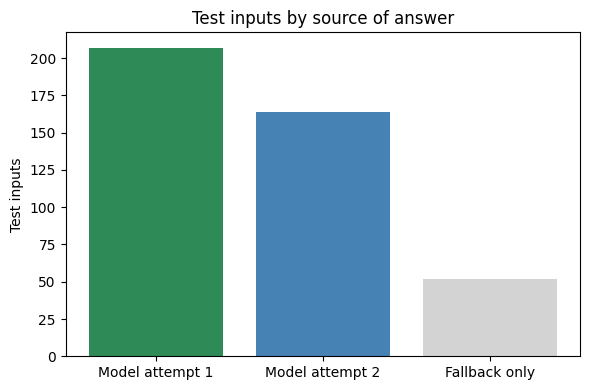

Paper zip rebuilt: /kaggle/working/arc_paper_artifacts.zip (316 KB)
VALIDATION PASSED: submission.json matches sample_submission.json (240 tasks, 259 test inputs).
SUBMISSION READY: save a version, then submit /kaggle/working/submission.json to the competition.


In [19]:
# CELL QW7 - Test inference, paper zip update, and submission.json (final cell)
import json
import glob
import time
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Confirm the objects from earlier cells are still in memory
needed = ["model", "tokenizer", "device", "OUT_DIR", "SEED", "to_np", "make_example", "generate_grid",
          "build_zip", "random_perm"]
missing = [n for n in needed if n not in globals()]
if missing:
    raise RuntimeError(f"Missing from memory: {missing}. Rerun the earlier cells in this session.")

# Settings
INFER_SECONDS = int(4.5 * 3600)   # total time limit for both passes (lower it if your GPU quota is shorter)
SAVE_EVERY = 5                    # save progress after this many generations
MAX_LEN = 5000                    # longest prompt (in tokens) that inference will try; generate_grid reads this global
PROGRESS_PATH = OUT_DIR / "test_progress.json"

# Put the adapter back to its QW4 state in case anything changed it
if "restore_adapter" in globals():
    restore_adapter()
model.eval()
model.config.use_cache = True

# Find the test challenges and the sample submission file
def find_file(name):
    hits = glob.glob(f"/kaggle/input/**/{name}", recursive=True)
    if not hits:
        raise FileNotFoundError(f"{name} not found under /kaggle/input")
    return hits[0]

test_path = find_file("arc-agi_test_challenges.json")
sample_path = find_file("sample_submission.json")
test = json.load(open(test_path))
sample = json.load(open(sample_path))
print(f"Test tasks: {len(test)} | test inputs: {sum(len(t['test']) for t in test.values())}")

# Build the list of test inputs, shortest prompt first
items = []
for tid, task in test.items():
    demos = [(to_np(p["input"]), to_np(p["output"])) for p in task["train"]]
    for idx, t in enumerate(task["test"]):
        test_in = to_np(t["input"])
        n_tok = len(tokenizer(make_example(demos, test_in))["input_ids"])
        items.append({"tid": tid, "idx": idx, "demos": demos, "test_in": test_in, "n_tok": n_tok})
items.sort(key=lambda d: d["n_tok"])

# Resume from saved progress if a previous run was interrupted
results = {}
if PROGRESS_PATH.exists():
    results = json.load(open(PROGRESS_PATH))
    print(f"Resuming: {len(results)} inputs already have saved results")

def key_of(it):
    return f"{it['tid']}|{it['idx']}"

def save_progress():
    json.dump(results, open(PROGRESS_PATH, "w"))

def safe_generate(it, t_idx, perm):
    # Generate one answer; return None if the prompt is too long, memory runs out, or the output is invalid
    try:
        g = generate_grid(it["demos"], it["test_in"], t_idx, perm)
    except torch.cuda.OutOfMemoryError:
        torch.cuda.empty_cache()
        return None
    torch.cuda.empty_cache()
    if g is None or g.ndim != 2 or not (1 <= g.shape[0] <= 30 and 1 <= g.shape[1] <= 30):
        return None
    return g.astype(int).tolist()

import torch
rng = random.Random(SEED + 11)
t_start = time.time()
n_done = 0

# Pass 1: attempt 1 for every input (no augmentation), shortest prompts first
for it in items:
    if time.time() - t_start > INFER_SECONDS:
        print("Time limit reached during pass 1")
        break
    rec = results.setdefault(key_of(it), {"a1": None, "a2": None, "a1_done": False})
    if rec["a1_done"]:
        continue
    if it["n_tok"] <= MAX_LEN:
        rec["a1"] = safe_generate(it, 0, np.arange(10))
    rec["a1_done"] = True
    n_done += 1
    if n_done % SAVE_EVERY == 0:
        save_progress()
        print(f"pass 1: {n_done} new | elapsed {time.time() - t_start:.0f}s | last task {it['tid']} ({it['n_tok']} tokens)")
save_progress()

# Pass 2: attempt 2 (one augmented generation), only while time remains
n2 = 0
for it in items:
    if time.time() - t_start > INFER_SECONDS:
        print("Time limit reached during pass 2")
        break
    rec = results.get(key_of(it))
    if rec is None or rec["a1"] is None or rec["a2"] is not None or rec.get("a2_done"):
        continue
    g2 = safe_generate(it, rng.randrange(1, 8), random_perm(rng))
    rec["a2_done"] = True
    if g2 is not None and g2 != rec["a1"]:
        rec["a2"] = g2                                # keep attempt 2 only if it differs from attempt 1
    n2 += 1
    if n2 % SAVE_EVERY == 0:
        save_progress()
        print(f"pass 2: {n2} done | elapsed {time.time() - t_start:.0f}s")
save_progress()

# Assemble the attempts, using fallback grids where the model gave none
entries, sources = {}, []
for it in items:
    rec = results.get(key_of(it), {"a1": None, "a2": None})
    fallback = it["test_in"].astype(int).tolist()
    a1 = rec["a1"] if rec["a1"] is not None else fallback
    if rec["a2"] is not None:
        a2 = rec["a2"]
    else:
        a2 = fallback if fallback != a1 else it["test_in"][::-1].astype(int).tolist()   # a different safe guess
    entries[(it["tid"], it["idx"])] = {"attempt_1": a1, "attempt_2": a2}
    sources.append({"task_id": it["tid"], "idx": it["idx"], "prompt_tokens": it["n_tok"],
                    "model_attempt_1": rec["a1"] is not None, "model_attempt_2": rec["a2"] is not None})

# Save a summary table and a plot for the paper
src_df = pd.DataFrame(sources)
src_df.to_csv(OUT_DIR / "tables" / "qwen_test_inference_summary.csv", index=False)
counts = {"Model attempt 1": int(src_df["model_attempt_1"].sum()),
          "Model attempt 2": int(src_df["model_attempt_2"].sum()),
          "Fallback only": int((~src_df["model_attempt_1"]).sum())}
display(pd.DataFrame([counts]))
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(list(counts.keys()), list(counts.values()), color=["seagreen", "steelblue", "lightgray"])
ax.set_title("Test inputs by source of answer")
ax.set_ylabel("Test inputs")
plt.tight_layout()
fig.savefig(OUT_DIR / "plots" / "qwen_test_inference_sources.png", dpi=120)
plt.show()

# Add the inference results to the README and rebuild the zip
with open(OUT_DIR / "README.md", "a", encoding="utf-8") as f:
    f.write(f"\n## Test inference\nInputs: {len(items)} | model attempt 1: {counts['Model attempt 1']} | "
            f"model attempt 2: {counts['Model attempt 2']} | fallback only: {counts['Fallback only']} | "
            f"time used: {time.time() - t_start:.0f}s\n")
zip_path = build_zip()
print(f"Paper zip rebuilt: {zip_path} ({zip_path.stat().st_size / 1024:.0f} KB)")

# Write submission.json last, in the same task order and structure as the sample file
submission = {}
for tid in sample:
    n_inputs = len(test[tid]["test"])
    submission[tid] = [entries[(tid, i)] for i in range(n_inputs)]
json.dump(submission, open("/kaggle/working/submission.json", "w"))

# Check the file against the sample submission
def valid_grid(g):
    return (isinstance(g, list) and 1 <= len(g) <= 30 and all(isinstance(r, list) and 1 <= len(r) <= 30 for r in g)
            and len({len(r) for r in g}) == 1 and all(isinstance(v, int) and 0 <= v <= 9 for r in g for v in r))

problems = []
if set(submission) != set(sample):
    problems.append("task ids differ from the sample")
for tid in sample:
    if len(submission.get(tid, [])) != len(sample[tid]):
        problems.append(f"{tid}: number of test inputs differs from the sample")
        continue
    for i, e in enumerate(submission[tid]):
        if set(e) != {"attempt_1", "attempt_2"}:
            problems.append(f"{tid}[{i}]: wrong attempt keys")
        elif not (valid_grid(e["attempt_1"]) and valid_grid(e["attempt_2"])):
            problems.append(f"{tid}[{i}]: invalid grid")
n_in = sum(len(v) for v in submission.values())
if problems:
    print(f"VALIDATION FAILED ({len(problems)} problems). First problems: {problems[:5]}")
else:
    print(f"VALIDATION PASSED: submission.json matches sample_submission.json ({len(submission)} tasks, {n_in} test inputs).")
    print("SUBMISSION READY: save a version, then submit /kaggle/working/submission.json to the competition.")